# Áreas de Superfícies Planas

**Módulo:** 04 – Geometria Plana (**notebook final do módulo**)

**Pré-requisitos:** [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) e [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (trapézio, base média, paralelogramo, losango), [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb) (triangulação em $n - 2$ triângulos), [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) e [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (círculo, arco, corda, flecha, ângulo central, coroa), [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (razão de semelhança), [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) e [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) (Pitágoras, Herão, $S = p \cdot r$, $S = \frac{abc}{4R}$), [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) ($S = p \cdot a$, $C = 2\pi r$, $\pi$ pelos polígonos) e [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb) (as fórmulas de área dos polígonos, equivalência e a razão $k^2$).

**Objetivos de aprendizagem:** ao final você será capaz de...
- **Deduzir** a área do círculo, $S = \pi r^2$, a partir dos polígonos regulares, e calcular as áreas do **setor**, do **segmento circular** e da **coroa circular**.
- Reunir as fórmulas de área do módulo e **escolher a mais adequada** a partir dos dados do problema, inclusive para um polígono qualquer (por decomposição ou por coordenadas).
- Resolver problemas de **regiões compostas e sombreadas** (soma, subtração, simetria, reorganização, proporção) e aplicar áreas em **escalas, unidades, custos e probabilidade geométrica**, estimando áreas por sorteio (**Monte Carlo**).
- **Revisar o módulo inteiro** e reconhecer quais ideias da Geometria Plana reaparecem nos módulos seguintes.

**Tempo estimado:** 90 a 105 minutos (é um notebook denso: vale dividir em duas sessões, uma para as seções 1 a 3 e outra para as seções 4 e 5 e o fechamento do módulo)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0420a_areas_de_superficies_planas.ipynb)

## Duas pizzas médias ou uma gigante?

Uma pizzaria vende dois tamanhos de pizza redonda, com a mesma espessura e a mesma cobertura:

- **média**: 30 cm de diâmetro;
- **gigante**: 45 cm de diâmetro.

Você e um amigo estão com fome. Qual pedido rende **mais pizza**: **duas médias** ou **uma gigante**?

Antes de rodar qualquer coisa, dê um palpite. Muita gente pensa assim: "duas médias somam $30 + 30 = 60$ cm de diâmetro, e a gigante tem só 45, então as duas médias ganham". Ou assim: "a gigante tem 1,5 vez o diâmetro da média; duas médias são 2 vezes a média; logo as duas médias ganham". Será?

### O alvo de dardos

Um alvo circular de raio 3 é dividido por duas circunferências de **mesmo centro**, de raios 1 e 2, em três regiões: o **centro** (o círculo de raio 1), o **anel do meio** e o **anel de fora**. Um dardo é lançado "às cegas" e cai num ponto qualquer do alvo, sem preferência por nenhuma parte.

> Qual é a chance de o dardo cair no centro? E no anel de fora?

O palpite mais comum é "um terço para cada região, já que são três regiões". Guarde o seu. A pizza será resolvida na **seção 1** e o alvo na **seção 2**; a ideia de "chance = área" volta, completa, na **seção 5**.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import Markdown, display
from matplotlib.patches import Circle, Polygon, Rectangle, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0402a, 0407a, 0410a, 0412a, 0418a e 0419a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def pe_da_altura(X, P, Q) -> np.ndarray:
    """Pé da perpendicular baixada de X sobre a reta PQ (0407a)."""
    X, P, Q = (np.asarray(Z, dtype=float) for Z in (X, P, Q))
    u = Q - P
    return P + np.dot(X - P, u) / np.dot(u, u) * u


def distancia_ponto_reta(X, P, Q) -> float:
    """Distância do ponto X à reta PQ: a medida de X até o pé da perpendicular (0407a)."""
    return math.dist(X, pe_da_altura(X, P, Q))


def incentro(A, B, C) -> np.ndarray:
    """Incentro: média dos vértices com pesos iguais aos lados opostos, (a·A + b·B + c·C)/(a + b + c) (0410a)."""
    A, B, C = (np.asarray(Z, dtype=float) for Z in (A, B, C))
    a, b, c = math.dist(B, C), math.dist(C, A), math.dist(A, B)
    return (a * A + b * B + c * C) / (a + b + c)


def circuncentro(A, B, C) -> np.ndarray:
    """Circuncentro: o ponto equidistante dos três vértices, solução de um sistema linear 2×2 (0410a e 0412a)."""
    A, B, C = (np.asarray(Z, dtype=float) for Z in (A, B, C))
    M = 2 * np.array([B - A, C - A])
    return np.linalg.solve(M, np.array([B @ B - A @ A, C @ C - A @ A]))


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=8)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=9)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 6) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=9)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def vertices_regular(n: int, R: float = 1.0, centro=(0.0, 0.0), rotacao: float | None = None) -> np.ndarray:
    """Vértices do polígono regular de n lados inscrito na circunferência λ(centro, R): n pontos dela separados
    por 360°/n, o primeiro na direção `rotacao` (em graus). Sem `rotacao`, o polígono fica "apoiado" num lado
    horizontal (0418a).

    (A direção de cada vértice usa `direcao`, que vem da Trigonometria; aqui ela só aponta os vértices.)
    """
    inicio = -90 - 180 / n if rotacao is None else rotacao
    c = np.asarray(centro, dtype=float)
    return np.array([c + R * direcao(inicio + 360 * k / n) for k in range(n)])


def area_cadarco(pontos) -> float:
    """Área de um polígono simples (lados que não se cruzam) a partir dos vértices EM ORDEM, pela fórmula do
    cadarço: S = |x₁y₂ − x₂y₁ + x₂y₃ − x₃y₂ + ... + xₙy₁ − x₁yₙ| / 2 (a "régua de área" de 0419a).

    A seção 3 deste notebook mostra de onde ela vem no caso do triângulo; a demonstração geral chega em
    Geometria Analítica (módulo 07).
    """
    P = np.asarray(pontos, dtype=float)
    x, y = P[:, 0], P[:, 1]
    return abs(float(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))) / 2


def desenhar_peca(ax, pontos, cor: str = COR_PONTO, opacidade: float = 0.55, borda: str = NORD_TEXTO,
                  largura: float = 1.5, estilo: str = "-", rotulo: str | None = None, tamanho: int = 11,
                  zorder: int = 3) -> None:
    """Desenha uma região (polígono) pintada, com contorno; `rotulo` é escrito no centro dela (0419a)."""
    P = np.asarray(pontos, dtype=float)
    ax.add_patch(Polygon(P, closed=True, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=zorder))
    ax.add_patch(Polygon(P, closed=True, fill=False, edgecolor=borda, lw=largura, linestyle=estilo,
                         zorder=zorder + 1))
    if rotulo:
        ax.text(*P.mean(axis=0), rotulo, color=NORD_TEXTO, fontsize=tamanho, fontweight="bold", ha="center",
                va="center", zorder=zorder + 2)


# Ferramentas novas deste notebook
# Cores fixas: círculo azul-claro; setor amarelo; triângulo central roxo; segmento circular verde; coroa laranja;
# parte que é subtraída vermelha; polígono que aproxima uma curva azul.
COR_CIRCULO = COR_PONTO  # círculo: azul-claro
COR_SETOR = COR_AVISO  # setor circular: amarelo
COR_TRIANGULO = COR_EXTRA  # triângulo central (dois raios e a corda): roxo
COR_SEGMENTO = COR_DESTAQUE  # segmento circular: verde
COR_COROA = "#D08770"  # coroa circular: laranja
COR_SUBTRAIDA = COR_ALERTA  # parte que é retirada (ou erro): vermelho
COR_POLIGONO = COR_SECUNDARIA  # polígono que aproxima a curva: azul
CORES_PECAS = ("#88C0D0", "#A3BE8C", "#EBCB8B", "#BF616A", "#B48EAD", "#D08770", "#81A1C1", "#8FBCBB", "#5E81AC")


def ponto_na_circunferencia(O, r: float, angulo_graus: float) -> np.ndarray:
    """O ponto da circunferência λ(O, r) na direção `angulo_graus`, vista a partir do centro (0412a)."""
    return np.asarray(O, dtype=float) + r * direcao(angulo_graus)


def pontos_arco(O, r: float, inicio: float, fim: float, n: int = 200) -> np.ndarray:
    """n + 1 pontos do arco de λ(O, r) que vai da direção `inicio` até a direção `fim` (em graus; se fim < inicio,
    o arco é percorrido no sentido horário). Ligados por segmentos, eles formam uma poligonal "colada" no arco:
    é assim que este notebook DESENHA as regiões curvas e as MEDE com a régua de área (area_cadarco)."""
    angulos = np.radians(np.linspace(inicio, fim, n + 1))
    return np.asarray(O, dtype=float) + r * np.column_stack([np.cos(angulos), np.sin(angulos)])


def regiao_circulo(O, r: float, n: int = 400) -> np.ndarray:
    """O círculo λ(O, r) aproximado por um polígono regular de n lados (para desenhar e para medir)."""
    return pontos_arco(O, r, 0, 360, n)[:-1]


def escrever_area(ax, P, texto: str, cor: str = NORD_TEXTO, tamanho: int = 12) -> None:
    """Escreve um rótulo de área em P, com uma "etiqueta" escura atrás para ficar legível sobre as cores."""
    ax.text(*P, texto, color=cor, fontsize=tamanho, fontweight="bold", ha="center", va="center", zorder=12,
            bbox={"boxstyle": "round,pad=0.25", "facecolor": NORD_FUNDO, "edgecolor": "none", "alpha": 0.75})

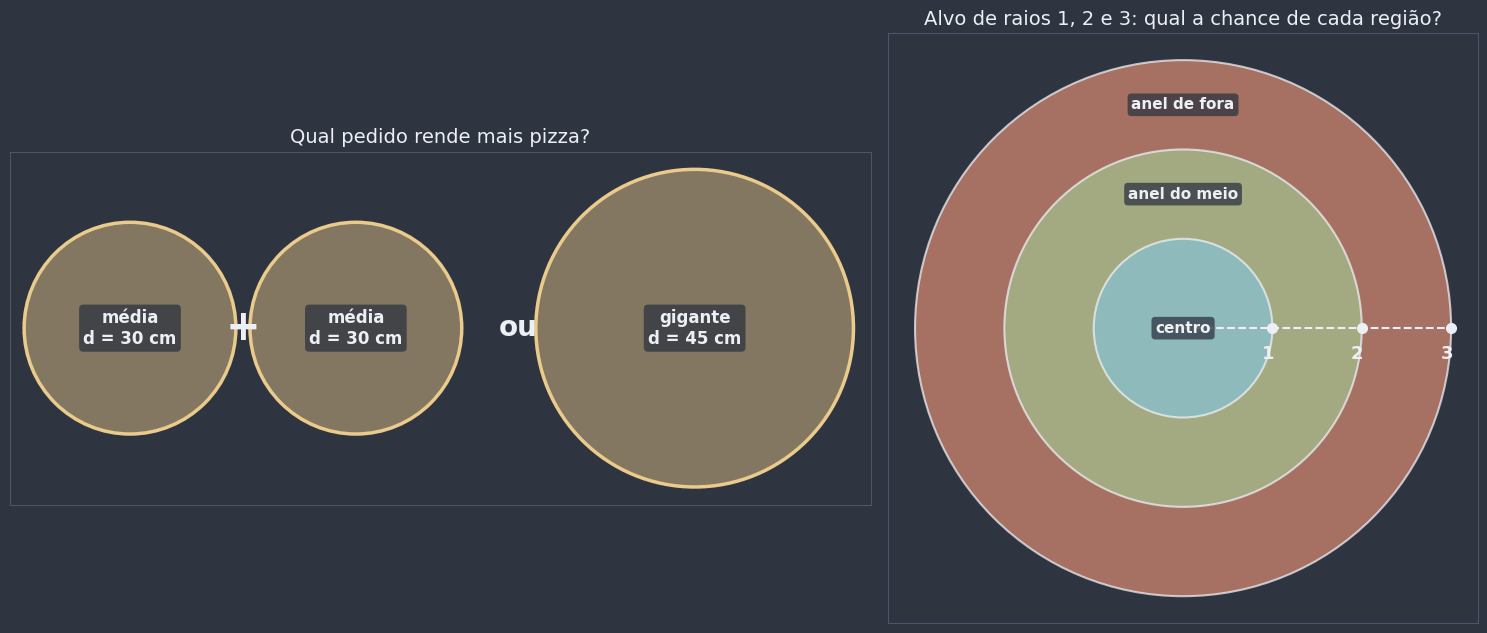

In [2]:
fig, (ax_p, ax_a) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.45, 1]})
fig.patch.set_facecolor(NORD_FUNDO)

# As pizzas, desenhadas na mesma escala (medidas em cm)
for centro, raio, nome in (((15, 0), 15, "média\nd = 30 cm"), ((47, 0), 15, "média\nd = 30 cm"),
                           ((95, 0), 22.5, "gigante\nd = 45 cm")):
    desenhar_circunferencia(ax_p, centro, raio, cor=COR_AVISO, preencher=True, opacidade=0.45)
    escrever_area(ax_p, centro, nome, tamanho=12)
ax_p.text(31, 0, "+", color=NORD_TEXTO, fontsize=30, ha="center", va="center", fontweight="bold")
ax_p.text(70, 0, "ou", color=NORD_TEXTO, fontsize=20, ha="center", va="center", fontweight="bold")
preparar_eixo(ax_p, [(0, -23), (118, 23)], margem=2)
ax_p.set_title("Qual pedido rende mais pizza?", color=NORD_TEXTO, fontsize=14)

# O alvo: três regiões delimitadas pelas circunferências de raios 1, 2 e 3
for raio, cor in ((3, COR_COROA), (2, COR_SEGMENTO), (1, COR_CIRCULO)):
    ax_a.add_patch(Circle((0, 0), raio, facecolor=cor, alpha=0.75, edgecolor=NORD_TEXTO, lw=1.5))
for texto, y in (("centro", 0), ("anel do meio", 1.5), ("anel de fora", 2.5)):
    escrever_area(ax_a, (0, y), texto, tamanho=11)
desenhar_segmento(ax_a, (0, 0), (3, 0), cor=NORD_TEXTO, largura=1.5, estilo="--")
for r in (1, 2, 3):
    desenhar_ponto(ax_a, (r, 0), str(r), cor=NORD_TEXTO, deslocamento=(-0.12, -0.35))
preparar_eixo(ax_a, [(-3, -3), (3, 3)], margem=0.3)
ax_a.set_title("Alvo de raios 1, 2 e 3: qual a chance de cada região?", color=NORD_TEXTO, fontsize=14)
plt.tight_layout()
plt.show()

Repare que a gigante **parece** bem maior que cada média (e é), mas comparar "duas contra uma" a olho é traiçoeiro. Precisamos de uma fórmula para a **área do círculo**: é o primeiro assunto do notebook.

**O caminho deste notebook:** o polígono regular, com $S = p \cdot a$ ([`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb)), vira o **círculo** quando o número de lados cresce; do círculo saem as suas **partes** (setor, segmento, coroa); com elas e com o **catálogo** das fórmulas dos polígonos, resolvemos **regiões compostas**; e terminamos com **aplicações** (escalas, custos, probabilidade). No fim, um **fechamento** do módulo inteiro.

📎 O **porquê** das fórmulas dos polígonos (cortar, deslizar e recolar; a razão $k^2$; Pitágoras por áreas) foi o assunto de [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb). Aqui essas demonstrações **não** são refeitas: usamos os resultados para **calcular, comparar e aplicar**.

**Notação fixa:** $S$ área; $r$ raio do círculo ($R$ o maior, em coroas e polígonos regulares); $C = 2\pi r$; $a$ apótema (no código, `apotema`); $p$ semiperímetro; $\alpha$ ângulo central, em graus; $\ell_{arco}$ comprimento do arco; $b$ e $h$ base e altura; $B$, $b$ e $h$ no trapézio. No código, sempre `math.pi`, nunca 3,14.

## 1. A área do círculo

### Do polígono regular ao círculo

Em [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) vimos que a área de um polígono regular é

$$S = p \cdot a \qquad (\text{semiperímetro} \times \text{apótema}),$$

porque ele se divide em $n$ triângulos congruentes de base $\ell$ e altura $a$ (e, em [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb), que ele é **equivalente** a um triângulo de base $2p$ e altura $a$).

Agora inscreva polígonos regulares numa circunferência de raio $r$ e **aumente o número de lados** $n$. O polígono vai "grudando" no círculo:

- o semiperímetro $p$ se aproxima da **metade da circunferência**: $p \to \frac{C}{2} = \frac{2\pi r}{2} = \pi r$;
- o apótema $a$ se aproxima do **raio**: $a \to r$ (a folga $r - a$ entre o lado e o arco some).

Logo a área $p \cdot a$ se aproxima de $\pi r \cdot r$:

$$\boxed{S_{círculo} = \pi r^2}$$

O sinal "$\to$" (se aproxima de) é a ideia de **limite**, que só será tratada com rigor nos módulos de Cálculo. Aqui vamos **ver** a convergência acontecer, como Arquimedes fez.

📌 **Definição formal:**
- Área do círculo de raio $r$: $S = \pi r^2$. Em função do diâmetro $d = 2r$: $S = \pi \left(\frac{d}{2}\right)^2 = \frac{\pi d^2}{4}$.
- Comprimento da circunferência (0418a): $C = 2\pi r$. **Não confunda:** $C$ é um comprimento (cm); $S$ é uma área (cm²).

A tabela abaixo usa só **Pitágoras**: começa no hexágono inscrito (lado $= r$) e vai **dobrando** o número de lados com a fórmula de dobra de 0418a, $\ell_{2n} = \sqrt{2r^2 - r\sqrt{4r^2 - \ell_n^2}}$; o apótema sai de $a = \sqrt{r^2 - (\ell/2)^2}$. Nenhum seno, nenhum cosseno.

In [2]:
def area_circulo(r: float) -> float:
    """Área do círculo de raio r: S = π·r²."""
    return math.pi * r**2


def area_circulo_diametro(d: float) -> float:
    """Área do círculo de diâmetro d: S = π·d²/4."""
    return math.pi * d**2 / 4


def dobrar_lado(lado: float, R: float = 1.0) -> float:
    """Lado ℓ₂ₙ do regular de 2n lados inscrito em λ(O, R), a partir do lado ℓₙ (Pitágoras duas vezes, 0418a)."""
    return math.sqrt(2 * R**2 - R * math.sqrt(4 * R**2 - lado**2))


def area_regular_inscrito(n: int, R: float = 1.0) -> float:
    """Área S = p·a do regular de n = 6·2ᵏ lados inscrito em λ(O, R), só com Pitágoras: começa no hexágono
    (lado = R) e dobra o número de lados até chegar a n."""
    lados, lado = 6, R
    while lados < n:
        lado, lados = dobrar_lado(lado, R), 2 * lados
    if lados != n:
        raise ValueError("use n = 6, 12, 24, 48, ... (o hexágono dobrado várias vezes)")
    apotema = math.sqrt(R**2 - (lado / 2) ** 2)
    return (n * lado / 2) * apotema


linhas, erro_anterior = [], None
for n in (6, 12, 24, 48, 96, 192, 384):
    S = area_regular_inscrito(n)
    erro = math.pi - S
    linhas.append({"n": n, "S = p·a (R = 1)": S, "π − S": erro,
                   "erro anterior / erro": erro_anterior / erro if erro_anterior else float("nan")})
    erro_anterior = erro
tabela_convergencia = pd.DataFrame(linhas)
display(tabela_convergencia.round(6))
print(f"π = {math.pi:.6f}")

# As áreas sobem sempre, ficam sempre abaixo de π e o erro cai (perto de 4 vezes a cada dobra)
areas = tabela_convergencia["S = p·a (R = 1)"].tolist()
assert all(x < y < math.pi for x, y in zip(areas, areas[1:]))
assert iguais(area_regular_inscrito(6), 3 * math.sqrt(3) / 2) and iguais(area_regular_inscrito(12), 3)
print("Hexágono: 3√3/2 ≈ 2,598; dodecágono: exatamente 3; as áreas sobem e nunca passam de π.  ✓")

,n,S = p·a (R = 1),π − S,erro anterior / erro
0,6,2.598076,0.543516,NaN
1,12,3.000000,0.141593,3.838592
2,24,3.105829,0.035764,3.959071
3,48,3.132629,0.008964,3.989731
4,96,3.139350,0.002242,3.997431
5,192,3.141032,0.000561,3.999357
6,384,3.141452,0.000140,3.999839


π = 3.141593
Hexágono: 3√3/2 ≈ 2,598; dodecágono: exatamente 3; as áreas sobem e nunca passam de π.  ✓


O dodecágono inscrito no círculo de raio 1 tem área **exatamente 3** (uma surpresa simpática), e o polígono de 96 lados, o mesmo que Arquimedes usou, já dá $3{,}139$. A última coluna mostra que **cada dobra divide o erro por quase 4**: dobrar $n$ divide o erro por $2^2$. Guarde esse "4": na seção 5, o método de Monte Carlo vai convergir **muito** mais devagar.

A representação gráfica: à esquerda, as áreas subindo até $\pi$; à direita, o erro em escala logarítmica (cada "degrau" do eixo vertical é uma casa decimal).

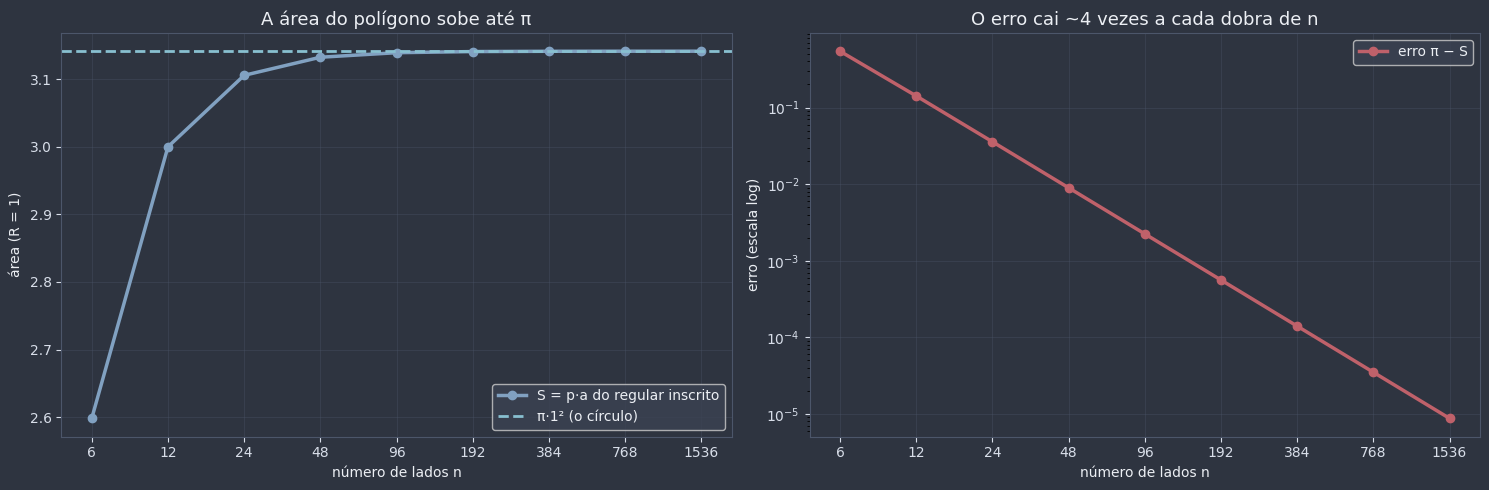

In [3]:
ns = [6 * 2**k for k in range(9)]
areas_n = [area_regular_inscrito(n) for n in ns]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
fig.patch.set_facecolor(NORD_FUNDO)
for ax in (ax1, ax2):
    estilizar_eixo(ax)
ax1.plot(ns, areas_n, "o-", color=COR_POLIGONO, lw=2.5, label="S = p·a do regular inscrito")
ax1.axhline(math.pi, color=COR_CIRCULO, ls="--", lw=2, label="π·1² (o círculo)")
ax1.set_xscale("log", base=2)
ax1.set_xticks(ns, [str(n) for n in ns])
ax1.set_xlabel("número de lados n", color=NORD_TEXTO)
ax1.set_ylabel("área (R = 1)", color=NORD_TEXTO)
ax1.set_title("A área do polígono sobe até π", color=NORD_TEXTO, fontsize=13)
ax1.legend(facecolor=NORD_PAINEL, labelcolor=NORD_TEXTO)

ax2.plot(ns, [math.pi - s for s in areas_n], "o-", color=COR_SUBTRAIDA, lw=2.5, label="erro π − S")
ax2.set_xscale("log", base=2)
ax2.set_yscale("log")
ax2.set_xticks(ns, [str(n) for n in ns])
ax2.set_xlabel("número de lados n", color=NORD_TEXTO)
ax2.set_ylabel("erro (escala log)", color=NORD_TEXTO)
ax2.set_title("O erro cai ~4 vezes a cada dobra de n", color=NORD_TEXTO, fontsize=13)
ax2.legend(facecolor=NORD_PAINEL, labelcolor=NORD_TEXTO)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — o polígono que vira círculo:** escolha o número de lados $n$ (de 3 a 100) e o raio $r$. O polígono regular inscrito (azul) aparece sobre o círculo, com um dos $n$ triângulos destacado (base $\ell$, altura $a$). O painel mostra $p$ chegando perto de $\pi r$, $a$ chegando perto de $r$ e a área $p \cdot a$ chegando perto de $\pi r^2$. Para $n$ qualquer (não só $6 \cdot 2^k$), o lado e o apótema são **medidos** nas coordenadas, como em 0418a.

In [4]:
def lado_e_apotema(n: int, R: float) -> tuple[float, float]:
    """Lado e apótema do regular de n lados inscrito em λ(O, R), MEDIDOS nas coordenadas dos vértices (0418a)."""
    V = vertices_regular(n, R)
    return math.dist(V[0], V[1]), math.dist((0, 0), ponto_medio(V[0], V[1]))


def area_regular(n: int, R: float = 1.0) -> float:
    """Área S = p·a do regular de n lados inscrito em λ(O, R) (0418a)."""
    lado, apotema = lado_e_apotema(n, R)
    return n * lado / 2 * apotema


def explorar_poligono_circulo(n: int, r: float) -> None:
    V = vertices_regular(n, r)
    lado, apotema = lado_e_apotema(n, r)
    p, S = n * lado / 2, area_regular(n, r)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.6), gridspec_kw={"width_ratios": [1.05, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_circunferencia(ax, (0, 0), r, cor=COR_CIRCULO, preencher=True, opacidade=0.25)
    desenhar_peca(ax, V, cor=COR_POLIGONO, opacidade=0.35, borda=COR_POLIGONO, largura=2)
    desenhar_peca(ax, [(0, 0), V[0], V[1]], cor=COR_TRIANGULO, opacidade=0.75, largura=1.2)
    M = ponto_medio(V[0], V[1])
    desenhar_segmento(ax, (0, 0), M, cor=COR_COROA, largura=2.5)
    desenhar_ponto(ax, (0, 0), "O", cor=NORD_TEXTO, deslocamento=(0.1 * r, 0.05 * r))
    ax.text(M[0], M[1] - 0.12 * r, "ℓ", color=COR_TRIANGULO, fontsize=14, fontweight="bold", ha="center")
    ax.text(0.08 * r, -0.45 * r, "a", color=COR_COROA, fontsize=14, fontweight="bold")
    preparar_eixo(ax, [(-5, -5), (5, 5)], margem=0.3)
    ax.set_title(f"Regular de {n} lados inscrito no círculo de raio {r:g}", color=NORD_TEXTO, fontsize=13)
    erro = area_circulo(r) - S
    itens = [
        (f"semiperímetro p = {p:.4f}   (πr = {math.pi * r:.4f})", True),
        (f"apótema a = {apotema:.4f}   (r = {r:g})", True),
        (f"área S = p·a = {S:.4f}", iguais(S, area_cadarco(V))),
        (f"área do círculo πr² = {area_circulo(r):.4f}", True),
        (f"falta cobrir: πr² − S = {erro:.4f}", erro > 0),
        (f"o polígono cobre {100 * S / area_circulo(r):.2f}% do círculo", True),
        (f"S/r² = {S / r**2:.4f}  (não depende de r: semelhança)", iguais(S / r**2, area_regular(n, 1))),
    ]
    escrever_checklist(ax_lista, itens, "Do polígono ao círculo")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_poligono_circulo,
                 n=widgets.IntSlider(value=6, min=3, max=100, description="n:"),
                 r=widgets.FloatSlider(value=4.0, min=1.0, max=5.0, step=0.5, description="r:"));

interactive(children=(IntSlider(value=6, description='n:', min=3), FloatSlider(value=4.0, description='r:', ma…

Com $n = 6$, o hexágono cobre cerca de 83% do círculo; com $n = 12$, 95%; com $n = 100$, 99,93%. A última linha do painel mostra outra coisa importante: $\frac{S}{r^2}$ **não depende do raio**, só de $n$. É a razão $k^2$ de 0419a: todos os polígonos regulares de $n$ lados são semelhantes, e todos os **círculos** também (qualquer círculo é uma ampliação de qualquer outro). Por isso a área do círculo é "um número fixo vezes $r^2$", e esse número é $\pi$.

### Um segundo olhar: a cebola desenrolada

Existe outra maneira, muito bonita, de enxergar $S = \pi r^2$. Pense no círculo como uma **cebola**: uma porção de **anéis finos** encaixados um dentro do outro, todos com o mesmo centro.

1. Divida o raio $r$ em $N$ partes iguais, de espessura $\frac{r}{N}$; isso corta o círculo em $N$ anéis.
2. Corte cada anel ao longo de um raio e **estique-o**: um anel fino de raio $\rho$ vira quase um **retângulo** de comprimento $2\pi\rho$ (o comprimento da circunferência, 0418a) e altura $\frac{r}{N}$.
3. **Empilhe** os retângulos, do maior (o anel de fora, comprimento $2\pi r$) ao menor (perto do centro, comprimento quase 0).

A pilha forma, cada vez melhor, um **triângulo** de base $C = 2\pi r$ e altura $r$, cuja área é

$$\frac{2\pi r \cdot r}{2} = \pi r^2.$$

Isto é, **o círculo é equivalente a um triângulo de base $C$ e altura $r$**: é a ideia de "cortar e recolar" de 0419a, aplicada a uma figura curva. A pilha de retângulos **por fora** (usando o raio externo de cada anel) tem área um pouco maior que $\pi r^2$; a pilha **por dentro** (raio interno), um pouco menor. As duas "espremem" o valor certo quando $N$ cresce, e a diferença entre elas é exatamente o retângulo de baixo, $2\pi r \cdot \frac{r}{N}$, que some quando $N$ cresce.

A figura abaixo mostra $N = 5$, $20$ e $100$ anéis.

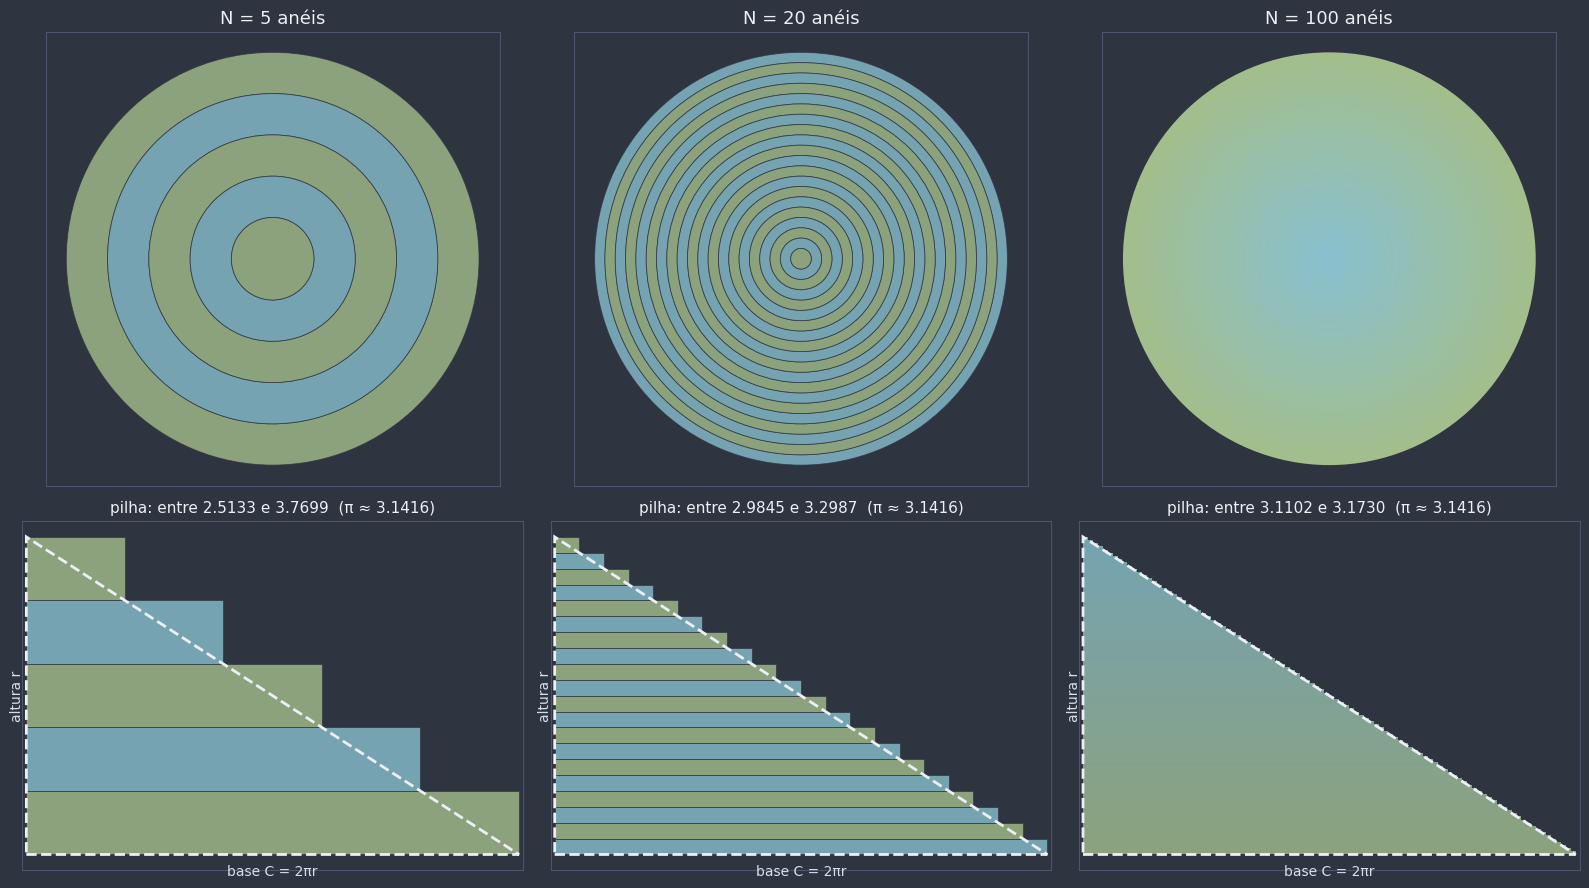

Para todo N: soma por dentro < π < soma por fora, e a diferença entre elas é 2π·r·(r/N) → 0.  ✓


In [5]:
def soma_aneis(r: float, N: int) -> tuple[float, float]:
    """Soma das áreas dos N retângulos da cebola desenrolada, por dentro (raio interno de cada anel)
    e por fora (raio externo): Σ 2π·ρ·(r/N)."""
    espessura = r / N
    por_dentro = sum(2 * math.pi * (k * espessura) * espessura for k in range(N))
    por_fora = sum(2 * math.pi * ((k + 1) * espessura) * espessura for k in range(N))
    return por_dentro, por_fora


def desenhar_cebola(ax_disco, ax_pilha, r: float, N: int) -> None:
    """À esquerda (ax_disco) o círculo cortado em N anéis; à direita (ax_pilha) os anéis esticados e empilhados
    (pilha por fora, colorida) sobre o triângulo de base 2πr e altura r (tracejado). Com poucos anéis, as cores
    se alternam; com muitos, mudam aos poucos do centro (azul) para fora (verde), como as camadas de uma cebola."""
    espessura = r / N
    degrade = plt.matplotlib.colors.LinearSegmentedColormap.from_list("cebola", [COR_CIRCULO, COR_SEGMENTO])

    def cor_do_anel(k: int) -> str:
        return CORES_PECAS[k % 2] if N <= 30 else degrade(k / N)

    borda = {"edgecolor": NORD_FUNDO, "lw": 0.6} if N <= 30 else {"edgecolor": "none", "lw": 0}
    for k in range(N, 0, -1):
        # Com muitos anéis, cada um é um disco opaco pintado sobre o anterior (sem frestas entre os anéis)
        anel = Wedge((0, 0), k * espessura, 0, 360, width=espessura, facecolor=cor_do_anel(k), alpha=0.8, **borda) \
            if N <= 30 else Circle((0, 0), k * espessura, facecolor=cor_do_anel(k), edgecolor="none")
        ax_disco.add_patch(anel)
    preparar_eixo(ax_disco, [(-r, -r), (r, r)], margem=0.1 * r)
    for k in range(1, N + 1):
        rho = k * espessura  # raio externo do anel
        y = r - rho  # o anel de fora fica embaixo
        ax_pilha.add_patch(Rectangle((0, y), 2 * math.pi * rho, espessura, facecolor=cor_do_anel(k), alpha=0.8,
                                     **borda))
    ax_pilha.add_patch(Polygon([(0, 0), (2 * math.pi * r, 0), (0, r)], closed=True, fill=False,
                               edgecolor=NORD_TEXTO, lw=2, ls="--", zorder=5))
    preparar_eixo(ax_pilha, [(0, 0), (2 * math.pi * r, r)], margem=0.05 * r)
    ax_pilha.set_aspect("auto")  # a pilha é muito mais larga que alta: esticamos a altura para enxergar os degraus
    ax_pilha.text(math.pi * r, -0.03 * r, "base C = 2πr", color=NORD_TEXTO_SEC, fontsize=10, ha="center", va="top")
    ax_pilha.text(-0.03 * r, r / 2, "altura r", color=NORD_TEXTO_SEC, fontsize=10, ha="right", va="center",
                  rotation=90)


r_cebola = 1.0
fig, eixos = plt.subplots(2, 3, figsize=(16, 9), gridspec_kw={"height_ratios": [1.3, 1]})
fig.patch.set_facecolor(NORD_FUNDO)
for coluna, N in enumerate((5, 20, 100)):
    desenhar_cebola(eixos[0, coluna], eixos[1, coluna], r_cebola, N)
    dentro, fora = soma_aneis(r_cebola, N)
    eixos[0, coluna].set_title(f"N = {N} anéis", color=NORD_TEXTO, fontsize=13)
    eixos[1, coluna].set_title(f"pilha: entre {dentro:.4f} e {fora:.4f}  (π ≈ {math.pi:.4f})",
                               color=NORD_TEXTO, fontsize=11)
plt.tight_layout()
plt.show()

for N in (5, 20, 100, 1000):
    dentro, fora = soma_aneis(1.0, N)
    assert dentro < math.pi < fora and iguais(fora - dentro, 2 * math.pi / N)
print("Para todo N: soma por dentro < π < soma por fora, e a diferença entre elas é 2π·r·(r/N) → 0.  ✓")

🕹️ **Widget interativo — a cebola:** mova o número de anéis $N$. A pilha por fora (colorida) sempre passa um pouquinho do triângulo tracejado; a pilha por dentro fica um pouquinho abaixo. Os números mostram as duas somas se aproximando de $\pi r^2$ (aqui com $r = 1$).

In [ ]:
def explorar_cebola(N: int) -> None:
    fig, (ax_d, ax_p, ax_lista) = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [0.8, 1.7, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_cebola(ax_d, ax_p, 1.0, N)
    ax_d.set_title(f"{N} anéis", color=NORD_TEXTO, fontsize=13)
    ax_p.set_title("anéis esticados e empilhados × triângulo de base 2π e altura 1", color=NORD_TEXTO, fontsize=12)
    dentro, fora = soma_aneis(1.0, N)
    itens = [
        (f"soma por dentro = {dentro:.5f}", dentro < math.pi),
        (f"soma por fora   = {fora:.5f}", fora > math.pi),
        (f"triângulo: 2π·1/2 = π = {math.pi:.5f}", True),
        (f"diferença fora − dentro = 2π/N = {fora - dentro:.5f}", iguais(fora - dentro, 2 * math.pi / N)),
        (f"média das duas = {(dentro + fora) / 2:.5f}", True),
    ]
    escrever_checklist(ax_lista, itens, "Espremendo π·r² (r = 1)")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_cebola, N=widgets.IntSlider(value=8, min=1, max=60, description="anéis N:"));

interactive(children=(IntSlider(value=8, description='anéis N:', max=60, min=1), Output()), _dom_classes=('wid…

(Curiosidade numérica: a **média** das duas pilhas dá exatamente $\pi$ para **qualquer** $N$. É que cada anel é, na verdade, exatamente equivalente a um **trapézio** de bases $2\pi\rho_{dentro}$ e $2\pi\rho_{fora}$: a média das duas pilhas é a pilha de trapézios, que forma o triângulo sem sobra. Mas isso usa a área da coroa, que só vamos calcular na seção 2.)

### Consequências imediatas

1. **Razão entre áreas de círculos.** Como todo círculo é semelhante a todo outro, com razão $k = \frac{r_2}{r_1}$, a razão entre as áreas é $k^2$ (0419a): $\dfrac{S_2}{S_1} = \left(\dfrac{r_2}{r_1}\right)^2$.
2. **Dobrar o raio quadruplica a área** (e triplicar multiplica por 9). Para **dobrar a área**, o raio cresce só $\sqrt{2} \approx 1{,}41$ vez.
3. **Pelo diâmetro:** $S = \frac{\pi d^2}{4}$. Usar $\pi d^2$ dá um valor **quatro vezes** maior.

📌 **Definição formal:** $S = \pi r^2 = \dfrac{\pi d^2}{4}$; para dois círculos, $\dfrac{S_2}{S_1} = \left(\dfrac{r_2}{r_1}\right)^2 = \left(\dfrac{d_2}{d_1}\right)^2$.

### Resposta ao gancho: as pizzas

- Média ($r = 15$ cm): $S = \pi \cdot 15^2 = 225\pi \approx 706{,}86$ cm². Duas médias: $450\pi \approx 1\,413{,}72$ cm².
- Gigante ($r = 22{,}5$ cm): $S = \pi \cdot 22{,}5^2 = 506{,}25\pi \approx 1\,590{,}43$ cm².

**A gigante rende mais**, cerca de 12,5% a mais que as duas médias juntas. O diâmetro cresceu 1,5 vez, então a área cresceu $1{,}5^2 = 2{,}25$ vezes: mais que o dobro.

In [7]:
media, gigante = area_circulo_diametro(30), area_circulo_diametro(45)
print(f"uma média:    π·15²   = {media:9.2f} cm²")
print(f"duas médias:  2·π·15² = {2 * media:9.2f} cm²")
print(f"uma gigante:  π·22,5² = {gigante:9.2f} cm²")
print(f"a gigante rende {100 * (gigante / (2 * media) - 1):.1f}% a mais; razão das áreas = (45/30)² = {(45 / 30) ** 2}")
assert gigante > 2 * media
assert iguais(gigante / media, (45 / 30) ** 2) and iguais(area_circulo(15), media)

# Dobrar o raio quadruplica a área; dobrar a área multiplica o raio por √2
for r in (1, 2.5, 10):
    assert iguais(area_circulo(2 * r) / area_circulo(r), 4)
    assert iguais(area_circulo(r * math.sqrt(2)), 2 * area_circulo(r))
print("Dobrar o raio quadruplica a área; para dobrar a área, o raio cresce √2 ≈ 1,414 vez.  ✓")

uma média:    π·15²   =    706.86 cm²
duas médias:  2·π·15² =   1413.72 cm²
uma gigante:  π·22,5² =   1590.43 cm²
a gigante rende 12.5% a mais; razão das áreas = (45/30)² = 2.25
Dobrar o raio quadruplica a área; para dobrar a área, o raio cresce √2 ≈ 1,414 vez.  ✓


🎯 **Aplicação prática — embalagens e cozinha:** a mesma conta vale para tampas, tortas, pratos e formas. Uma forma redonda de 24 cm de diâmetro tem $\left(\frac{24}{20}\right)^2 = 1{,}44$ vez a área de uma de 20 cm: uma receita feita para a forma de 20 cm precisa de **44% a mais** de massa (e não 20%) para ficar com a mesma altura na de 24 cm.

🕵️ **Curiosidade histórica:** a ideia de que o círculo é equivalente a um triângulo retângulo de catetos $r$ e $C$ costuma ser atribuída a **Arquimedes** (século III a.C.), num texto conhecido como *A Medida do Círculo*, o mesmo em que ele cercou $\pi$ com polígonos de 96 lados (0418a). Repare em algo nada óbvio: o $\pi$ da **área** ($S = \pi r^2$) é o **mesmo** $\pi$ do **comprimento** ($C = 2\pi r$). A cebola explica por quê: a área é feita de circunferências empilhadas. E isso fecha a história da **quadratura do círculo** de 0419a: para construir um quadrado de área $\pi r^2$, o lado teria de ser $\sqrt{\pi} \cdot r$, e, como $\pi$ é **transcendente** (resultado demonstrado por Lindemann em 1882), $\sqrt{\pi}$ não pode ser construído com régua e compasso.

⚠️ **Erro comum: confundir $\pi r^2$ com $2\pi r$.** $2\pi r$ é o **contorno** (cm); $\pi r^2$ é a **região** (cm²). Uma pista: na área sempre aparece um "quadrado" ($r^2$, $d^2$), porque área é comprimento × comprimento.

⚠️ **Erro comum: usar o diâmetro no lugar do raio.** $\pi \cdot 30^2$ **não** é a área da pizza de 30 cm de diâmetro; é quatro vezes ela. Ou use $r = 15$, ou use $\frac{\pi d^2}{4}$.

⚠️ **Erro comum: achar que dobrar o raio dobra a área.** Dobrar o raio **quadruplica** a área. É exatamente o engano do gancho: "1,5 vez o diâmetro" não é "1,5 vez a pizza", é $2{,}25$ vezes.

📖 **Leitura complementar:** [Pi](https://pt.wikipedia.org/wiki/Pi) (a história de $\pi$ e o método dos polígonos) e [Círculo](https://pt.wikipedia.org/wiki/C%C3%ADrculo) (definição e propriedades; repare que a fórmula da área foi deduzida aqui, no próprio notebook)

**Pergunta de checagem:** um círculo tem raio 5 cm. Qual é a sua área? E qual é o raio de um círculo com o **dobro** dessa área?

**Pergunta de checagem:** por que o $\pi$ que aparece na área do círculo é o mesmo $\pi$ do comprimento da circunferência?

## 2. Partes do círculo: setor, segmento circular e coroa

Com a área do círculo inteiro em mãos, as suas **partes** saem por proporção, por subtração ou pelas duas coisas.

### 2.1 Setor circular

O **setor circular** é a "fatia de pizza": a região limitada por **dois raios** e pelo **arco** entre eles ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) e [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb)). Fatias de mesmo ângulo central são congruentes (um giro leva uma na outra), então a área é **proporcional ao ângulo central** $\alpha$: o setor de $360°$ é o círculo inteiro, o de $180°$ é metade, o de $\alpha$ é a fração $\frac{\alpha}{360°}$:

$$S_{setor} = \frac{\alpha}{360°} \cdot \pi r^2.$$

Como o comprimento do arco é $\ell_{arco} = \frac{\alpha}{360°} \cdot 2\pi r$ (0418a), dá para escrever a mesma área de outro jeito:

$$S_{setor} = \frac{\ell_{arco} \cdot r}{2}.$$

É a estrutura "**base × altura / 2**" do triângulo: o setor é um "triângulo" de base $\ell_{arco}$ (curva) e altura $r$, exatamente como o círculo inteiro é o triângulo de base $C$ e altura $r$ (a cebola). Exemplo: $r = 6$ e $\alpha = 60°$ dão $\ell_{arco} = 2\pi$ e $S = \frac{60}{360} \cdot 36\pi = 6\pi \approx 18{,}85$ (ou $\frac{2\pi \cdot 6}{2} = 6\pi$).

### 2.2 Segmento circular

O **segmento circular** é a região entre uma **corda** e o **arco** que ela determina (0412a). Para $\alpha < 180°$, ele é o setor **menos** o triângulo formado pelos dois raios e pela corda:

$$S_{segmento} = S_{setor} - S_{triângulo}.$$

E a área desse triângulo sai **sem trigonometria**: ele é isósceles (dois lados são raios), a sua base é a corda e a sua altura é a **distância $d$ do centro à corda**. Como o raio perpendicular à corda a divide ao meio (0412a), Pitágoras dá

$$d = \sqrt{r^2 - \left(\tfrac{\text{corda}}{2}\right)^2}, \qquad S_{triângulo} = \frac{\text{corda} \cdot d}{2}.$$

Exemplo: $r = 6$ e $\alpha = 60°$. O triângulo central tem dois lados 6 e ângulo de $60°$ entre eles: é **equilátero**, então a corda mede 6 e $d = \sqrt{36 - 9} = 3\sqrt{3}$. Triângulo: $\frac{6 \cdot 3\sqrt{3}}{2} = 9\sqrt{3} \approx 15{,}59$. Segmento: $6\pi - 9\sqrt{3} \approx 3{,}26$.

**E se $\alpha > 180°$?** Aí o centro fica **dentro** do segmento (é o pedaço "grande" da pizza cortada por uma reta), e o triângulo deve ser **somado**: $S_{segmento} = S_{setor} + S_{triângulo}$. Para $\alpha = 180°$, a corda é um diâmetro, o triângulo "achata" (área zero) e o segmento é um semicírculo.

### 2.3 Coroa circular

A **coroa circular** (o "anel") é a região entre duas circunferências de **mesmo centro**, de raios $R > r$. Em 0412a só a definição foi dada; a área é o círculo grande **menos** o pequeno:

$$S_{coroa} = \pi R^2 - \pi r^2 = \pi (R^2 - r^2) = \pi (R - r)(R + r).$$

Leia a última forma assim: $2\pi \cdot \frac{R + r}{2}$ é o comprimento da **circunferência média** e $R - r$ é a **largura** do anel. A coroa equivale a um retângulo de **comprimento médio × largura**: é o "anel desenrolado" da cebola (que, na verdade, vira um trapézio de bases $2\pi r$ e $2\pi R$, com a mesma área).

💡 **O problema da anilha (um resultado surpreendente):** trace uma corda da circunferência **externa** que seja **tangente** à interna, de comprimento $c$. Então

$$S_{coroa} = \frac{\pi c^2}{4},$$

**sem precisar saber $R$ nem $r$!** Por quê: o raio $r$ até o ponto de tangência é perpendicular à corda (0412a), e essa perpendicular pelo centro divide a corda ao meio. No triângulo retângulo de hipotenusa $R$ e catetos $r$ e $\frac{c}{2}$, Pitágoras (0416a) dá $R^2 - r^2 = \frac{c^2}{4}$. Exemplo: $R = 5$ e $r = 3$ dão $c = 2\sqrt{25 - 9} = 8$ e $S = 16\pi \approx 50{,}27$, tanto por $\pi(25 - 9)$ quanto por $\frac{\pi \cdot 64}{4}$.

📌 **Definição formal:**
- $S_{setor} = \dfrac{\alpha}{360°} \pi r^2 = \dfrac{\ell_{arco} \cdot r}{2}$
- $S_{segmento} = S_{setor} - S_{triângulo}$ para $\alpha < 180°$ (e $+$ para $\alpha > 180°$), com $S_{triângulo} = \dfrac{\text{corda} \cdot d}{2}$ e $d = \sqrt{r^2 - (\text{corda}/2)^2}$
- $S_{coroa} = \pi(R^2 - r^2)$; corda da externa tangente à interna: $S_{coroa} = \dfrac{\pi c^2}{4}$

No código, a corda é **medida** nas coordenadas (a distância entre as duas pontas do arco, como o lado em 0418a), e $d$ sai de Pitágoras. Cada fórmula é conferida com a régua de área: a região curva é aproximada por uma poligonal com centenas de pontos sobre o arco.

In [8]:
def comprimento_arco(r: float, alfa: float) -> float:
    """Comprimento do arco de α graus numa circunferência de raio r: (α/360°)·2πr (0418a)."""
    return alfa / 360 * 2 * math.pi * r


def area_setor(r: float, alfa: float) -> float:
    """Área do setor de α graus: (α/360°)·πr²."""
    return alfa / 360 * area_circulo(r)


def corda_e_distancia(r: float, alfa: float) -> tuple[float, float]:
    """Corda que fecha o arco de α graus (medida entre as duas pontas do arco) e distância d do centro a ela,
    por Pitágoras: d = √(r² − (corda/2)²)."""
    A, B = ponto_na_circunferencia((0, 0), r, 0), ponto_na_circunferencia((0, 0), r, alfa)
    corda = math.dist(A, B)
    return corda, math.sqrt(max(r**2 - (corda / 2) ** 2, 0.0))


def area_triangulo_central(r: float, alfa: float) -> float:
    """Área do triângulo formado pelos dois raios e pela corda: corda × d / 2."""
    corda, d = corda_e_distancia(r, alfa)
    return corda * d / 2


def area_segmento(r: float, alfa: float) -> float:
    """Área do segmento circular entre a corda e o arco de α graus: setor − triângulo se α < 180°;
    setor + triângulo se α > 180° (o centro fica dentro do segmento); semicírculo se α = 180°."""
    if alfa < 180:
        return area_setor(r, alfa) - area_triangulo_central(r, alfa)
    return area_setor(r, alfa) + area_triangulo_central(r, alfa)


def area_coroa(R: float, r: float) -> float:
    """Área da coroa circular entre as circunferências concêntricas de raios R > r: π(R² − r²)."""
    return math.pi * (R**2 - r**2)


def area_coroa_por_corda(c: float) -> float:
    """Área da coroa a partir da corda c da externa que é tangente à interna: πc²/4."""
    return math.pi * c**2 / 4


# Os exemplos do texto
assert iguais(area_setor(6, 60), 6 * math.pi) and iguais(comprimento_arco(6, 60), 2 * math.pi)
assert iguais(area_setor(6, 60), comprimento_arco(6, 60) * 6 / 2)
assert iguais(corda_e_distancia(6, 60)[0], 6) and iguais(corda_e_distancia(6, 60)[1], 3 * math.sqrt(3))
assert iguais(area_segmento(6, 60), 6 * math.pi - 9 * math.sqrt(3))
assert iguais(area_coroa(5, 3), 16 * math.pi) and iguais(area_coroa_por_corda(8), 16 * math.pi)
print(f"setor (r = 6, α = 60°)    = 6π       ≈ {area_setor(6, 60):.4f}")
print(f"triângulo central         = 9√3      ≈ {area_triangulo_central(6, 60):.4f}")
print(f"segmento                  = 6π − 9√3 ≈ {area_segmento(6, 60):.4f}")
print(f"coroa (R = 5, r = 3)      = 16π      ≈ {area_coroa(5, 3):.4f}   (pela corda tangente c = 8: {area_coroa_por_corda(8):.4f})")

# Conferência com a régua de área: arco com muitos pontos, fechado pela corda (ou pelos dois raios)
linhas = []
for r, alfa in ((6, 60), (6, 90), (10, 90), (4, 150), (4, 180), (5, 240), (3, 330)):
    arco = pontos_arco((0, 0), r, 0, alfa, 4000)
    setor_num = area_cadarco(np.vstack([[(0, 0)], arco]))
    segmento_num = area_cadarco(arco)  # a poligonal do arco, fechada pela corda
    assert abs(setor_num - area_setor(r, alfa)) < 1e-4 * r**2 and abs(segmento_num - area_segmento(r, alfa)) < 1e-4 * r**2
    linhas.append({"r": r, "α": alfa, "setor (fórmula)": area_setor(r, alfa), "setor (régua)": setor_num,
                   "segmento (fórmula)": area_segmento(r, alfa), "segmento (régua)": segmento_num})
display(pd.DataFrame(linhas).round(4))

# Anilha: para quaisquer R > r, a corda tangente (medida) dá a mesma área
for R, r in ((5, 3), (13, 5), (2, 1.9), (10, 0.5)):
    T = np.array([0.0, r])  # ponto de tangência no "topo" da interna; a corda é horizontal
    meia_corda = math.sqrt(R**2 - r**2)
    c = math.dist(T - (meia_corda, 0), T + (meia_corda, 0))
    assert iguais(area_coroa(R, r), area_coroa_por_corda(c))
print("Fórmulas conferidas com a régua de área (até α > 180°), e a anilha confere para vários R e r.  ✓")

setor (r = 6, α = 60°)    = 6π       ≈ 18.8496
triângulo central         = 9√3      ≈ 15.5885
segmento                  = 6π − 9√3 ≈ 3.2611
coroa (R = 5, r = 3)      = 16π      ≈ 50.2655   (pela corda tangente c = 8: 50.2655)


,r,α,setor (fórmula),setor (régua),segmento (fórmula),segmento (régua)
0,6,60,18.8496,18.8496,3.2611,3.2611
1,6,90,28.2743,28.2743,10.2743,10.2743
2,10,90,78.5398,78.5398,28.5398,28.5398
3,4,150,20.9440,20.9439,16.9440,16.9439
4,4,180,25.1327,25.1327,25.1327,25.1327
5,5,240,52.3599,52.3599,63.1852,63.1852
6,3,330,25.9181,25.9181,28.1681,28.1681


Fórmulas conferidas com a régua de área (até α > 180°), e a anilha confere para vários R e r.  ✓


A representação gráfica das três partes, com as cores fixas do notebook: **setor** amarelo, **triângulo central** roxo, **segmento** verde e **coroa** laranja.

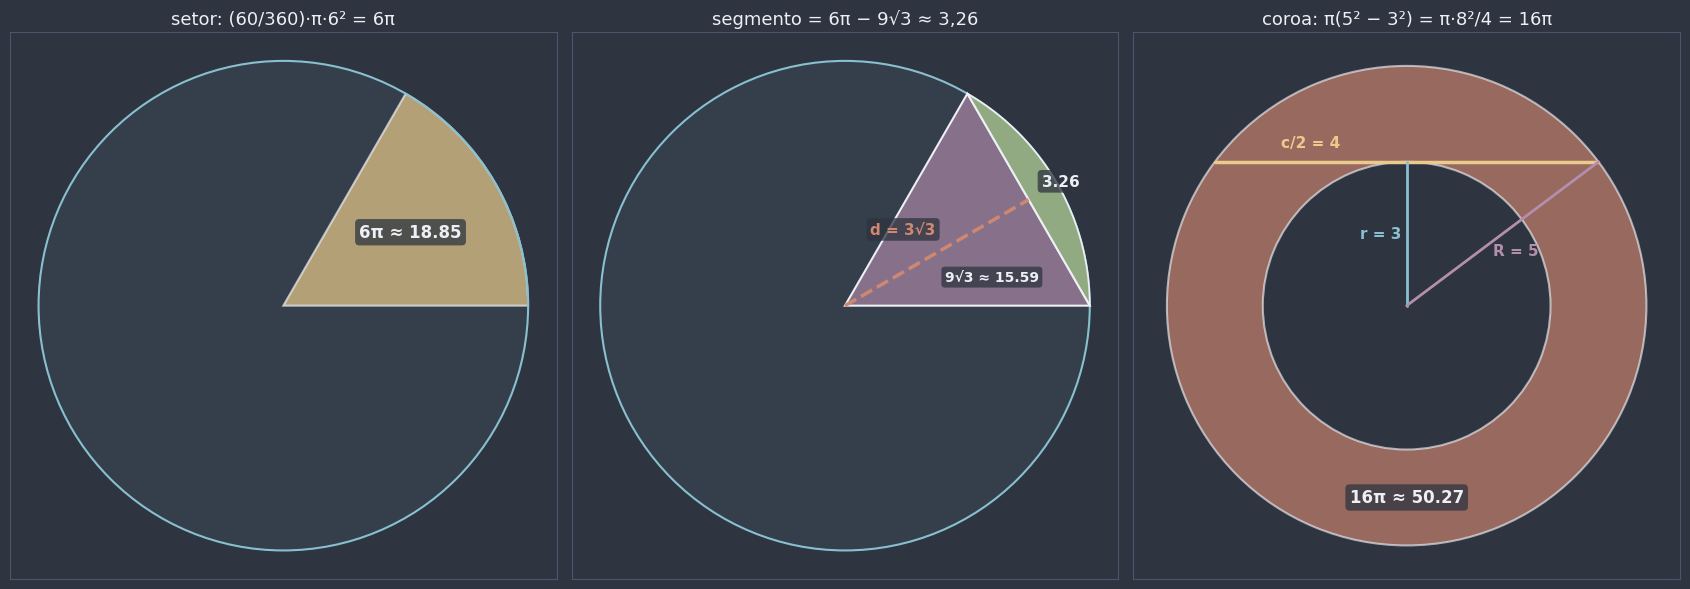

In [9]:
fig, eixos = plt.subplots(1, 3, figsize=(17, 5.8))
fig.patch.set_facecolor(NORD_FUNDO)
r, alfa = 6, 60
A, B = ponto_na_circunferencia((0, 0), r, 0), ponto_na_circunferencia((0, 0), r, alfa)

# Setor
ax = eixos[0]
desenhar_circunferencia(ax, (0, 0), r, cor=COR_CIRCULO, preencher=True, opacidade=0.08, largura=1.5)
ax.add_patch(Wedge((0, 0), r, 0, alfa, facecolor=COR_SETOR, alpha=0.7, edgecolor=NORD_TEXTO, lw=1.5))
escrever_area(ax, ponto_na_circunferencia((0, 0), 0.6 * r, alfa / 2), f"6π ≈ {area_setor(r, alfa):.2f}")
ax.set_title("setor: (60/360)·π·6² = 6π", color=NORD_TEXTO, fontsize=13)

# Segmento = setor − triângulo
ax = eixos[1]
desenhar_circunferencia(ax, (0, 0), r, cor=COR_CIRCULO, preencher=True, opacidade=0.08, largura=1.5)
desenhar_peca(ax, [(0, 0), A, B], cor=COR_TRIANGULO, opacidade=0.65)
desenhar_peca(ax, pontos_arco((0, 0), r, 0, alfa), cor=COR_SEGMENTO, opacidade=0.85, largura=1.2)
M = ponto_medio(A, B)
desenhar_segmento(ax, (0, 0), M, cor=COR_COROA, largura=2.5, estilo="--")
escrever_area(ax, 0.45 * M + np.array([-0.6, 0.7]), "d = 3√3", cor=COR_COROA, tamanho=11)
escrever_area(ax, (A + B) / 2 + 0.9 * direcao(alfa / 2), f"{area_segmento(r, alfa):.2f}", tamanho=11)
escrever_area(ax, (3.6, 0.7), f"9√3 ≈ {area_triangulo_central(r, alfa):.2f}", tamanho=10)
ax.set_title("segmento = 6π − 9√3 ≈ 3,26", color=NORD_TEXTO, fontsize=13)

# Coroa e a corda tangente
ax = eixos[2]
R2, r2 = 5, 3
ax.add_patch(Wedge((0, 0), R2, 0, 360, width=R2 - r2, facecolor=COR_COROA, alpha=0.65, edgecolor=NORD_TEXTO, lw=1.5))
desenhar_segmento(ax, (-4, 3), (4, 3), cor=COR_AVISO, largura=2.5)
desenhar_segmento(ax, (0, 0), (0, 3), cor=COR_CIRCULO, largura=2)
desenhar_segmento(ax, (0, 0), (4, 3), cor=COR_TRIANGULO, largura=2)
rotular_segmento(ax, (-4, 3), (0, 3), "c/2 = 4", cor=COR_AVISO, distancia=0.4, longe_de=(0, 0))
rotular_segmento(ax, (0, 0), (0, 3), "r = 3", cor=COR_CIRCULO, distancia=0.55)
rotular_segmento(ax, (0, 0), (4, 3), "R = 5", cor=COR_TRIANGULO, distancia=0.45, longe_de=(0, 3))
escrever_area(ax, (0, -4), f"16π ≈ {area_coroa(R2, r2):.2f}")
ax.set_title("coroa: π(5² − 3²) = π·8²/4 = 16π", color=NORD_TEXTO, fontsize=13)
for ax, lim in zip(eixos, (6.5, 6.5, 5.5)):
    preparar_eixo(ax, [(-lim, -lim), (lim, lim)], margem=0.2)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — setor, triângulo e segmento:** mova o raio $r$ e o ângulo central $\alpha$ (de 5° a 355°). O painel mostra as três áreas e confere a relação **setor = triângulo + segmento** (para $\alpha < 180°$) ou **segmento = setor + triângulo** (para $\alpha > 180°$). Passe de $\alpha = 170°$ para $\alpha = 190°$ e veja o triângulo "trocar de lado".

In [10]:
def explorar_setor(r: float, alfa: float) -> None:
    A, B = ponto_na_circunferencia((0, 0), r, 0), ponto_na_circunferencia((0, 0), r, alfa)
    corda, d = corda_e_distancia(r, alfa)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1, 1.05]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_circunferencia(ax, (0, 0), r, cor=COR_CIRCULO, preencher=True, opacidade=0.08, largura=1.5)
    ax.add_patch(Wedge((0, 0), r, 0, alfa, facecolor=COR_SETOR, alpha=0.25, edgecolor=COR_SETOR, lw=2))
    desenhar_peca(ax, pontos_arco((0, 0), r, 0, alfa), cor=COR_SEGMENTO, opacidade=0.6, largura=1.5)
    if not math.isclose(alfa, 180):
        desenhar_peca(ax, [(0, 0), A, B], cor=COR_TRIANGULO, opacidade=0.6, largura=1.2, zorder=5)
    desenhar_ponto(ax, (0, 0), "O", cor=NORD_TEXTO)
    preparar_eixo(ax, [(-10, -10), (10, 10)], margem=0.3)
    ax.set_title(f"r = {r:g}, α = {alfa:g}°", color=NORD_TEXTO, fontsize=13)
    S_setor, S_tri, S_seg = area_setor(r, alfa), area_triangulo_central(r, alfa), area_segmento(r, alfa)
    S_regua = area_cadarco(pontos_arco((0, 0), r, 0, alfa, 3000))
    if alfa < 180:
        relacao = (f"setor = triângulo + segmento: {S_tri:.3f} + {S_seg:.3f}", iguais(S_setor, S_tri + S_seg))
    else:
        relacao = (f"segmento = setor + triângulo: {S_setor:.3f} + {S_tri:.3f}", iguais(S_seg, S_setor + S_tri))
    itens = [
        (f"arco ℓ = (α/360°)·2πr = {comprimento_arco(r, alfa):.3f}", True),
        (f"setor = (α/360°)·πr² = {S_setor:.3f}   (= ℓ·r/2)", iguais(S_setor, comprimento_arco(r, alfa) * r / 2)),
        (f"corda = {corda:.3f}   d = √(r² − (corda/2)²) = {d:.3f}", True),
        (f"triângulo = corda·d/2 = {S_tri:.3f}", True),
        (f"segmento = {S_seg:.3f}", True),
        relacao,
        (f"segmento pela régua de área: {S_regua:.3f}", abs(S_regua - S_seg) < 1e-3 * r**2),
        (f"segmento + o resto do círculo = πr² = {area_circulo(r):.3f}",
         iguais(S_seg + area_segmento(r, 360 - alfa), area_circulo(r))),
    ]
    escrever_checklist(ax_lista, itens, "Setor, triângulo central e segmento")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_setor,
                 r=widgets.FloatSlider(value=6, min=1, max=10, step=0.5, description="r:"),
                 alfa=widgets.FloatSlider(value=60, min=5, max=355, step=5, description="α (graus):"));

interactive(children=(FloatSlider(value=6.0, description='r:', max=10.0, min=1.0, step=0.5), FloatSlider(value…

A última linha do painel é uma conferência elegante: a corda divide o círculo em **dois** segmentos, um de ângulo $\alpha$ e outro de $360° - \alpha$, e a soma dos dois é o círculo inteiro. Ela só funciona porque a regra "somar o triângulo quando $\alpha > 180°$" está certa.

🕹️ **Widget interativo — a coroa e a anilha:** escolha os raios $R$ e $r$ (o programa usa sempre $R$ como o maior). A corda amarela da circunferência externa é tangente à interna; o painel compara $\pi(R^2 - r^2)$ com $\frac{\pi c^2}{4}$ e com o "retângulo" de comprimento médio × largura.

In [ ]:
def explorar_coroa(R: float, r: float) -> None:
    R, r = max(R, r), min(R, r)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.05]})
    fig.patch.set_facecolor(NORD_FUNDO)
    if math.isclose(R, r):
        escrever_checklist(ax_lista, [("R = r: não há coroa (área zero)", False)], "Coroa circular")
        preparar_eixo(ax, [(-6, -6), (6, 6)], margem=0.2)
        desenhar_circunferencia(ax, (0, 0), R, cor=COR_COROA)
        plt.tight_layout()
        plt.show()
        return
    ax.add_patch(Wedge((0, 0), R, 0, 360, width=R - r, facecolor=COR_COROA, alpha=0.6, edgecolor=NORD_TEXTO, lw=1.5))
    meia = math.sqrt(R**2 - r**2)
    desenhar_segmento(ax, (-meia, r), (meia, r), cor=COR_AVISO, largura=2.5)
    desenhar_segmento(ax, (0, 0), (0, r), cor=COR_CIRCULO, largura=2)
    desenhar_segmento(ax, (0, 0), (meia, r), cor=COR_TRIANGULO, largura=2)
    desenhar_ponto(ax, (0, r), "T", cor=COR_AVISO, deslocamento=(0.1, 0.15))
    preparar_eixo(ax, [(-6, -6), (6, 6)], margem=0.2)
    ax.set_title(f"R = {R:g}, r = {r:g}", color=NORD_TEXTO, fontsize=13)
    c = 2 * meia
    itens = [
        (f"coroa = π(R² − r²) = {area_coroa(R, r):.4f}", True),
        (f"πR² − πr² = {area_circulo(R):.3f} − {area_circulo(r):.3f}", iguais(area_coroa(R, r), area_circulo(R) - area_circulo(r))),
        (f"corda tangente c = 2√(R² − r²) = {c:.4f}", True),
        (f"πc²/4 = {area_coroa_por_corda(c):.4f}", iguais(area_coroa_por_corda(c), area_coroa(R, r))),
        (f"comprimento médio × largura = {2 * math.pi * (R + r) / 2:.3f} × {R - r:g}",
         iguais(2 * math.pi * (R + r) / 2 * (R - r), area_coroa(R, r))),
        (f"⚠ π(R − r)² = {math.pi * (R - r) ** 2:.4f} (NÃO é a coroa)", False),
    ]
    escrever_checklist(ax_lista, itens, "Coroa circular")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_coroa,
                 R=widgets.FloatSlider(value=5, min=0.5, max=6, step=0.5, description="R:"),
                 r=widgets.FloatSlider(value=3, min=0.5, max=6, step=0.5, description="r:"));

interactive(children=(FloatSlider(value=5.0, description='R:', max=6.0, min=0.5, step=0.5), FloatSlider(value=…

### Resposta ao gancho: o alvo de dardos

No alvo de raios 1, 2 e 3:

- **centro:** $\pi \cdot 1^2 = \pi$;
- **anel do meio:** $\pi(2^2 - 1^2) = 3\pi$;
- **anel de fora:** $\pi(3^2 - 2^2) = 5\pi$;
- **alvo inteiro:** $\pi \cdot 3^2 = 9\pi$.

Se o dardo cai "sem preferência", a chance de cada região é a **fração da área** que ela ocupa: $\frac{1}{9}$, $\frac{3}{9}$ e $\frac{5}{9}$. Nada de "um terço para cada": o anel de fora é **cinco vezes** mais provável que o centro.

E repare nos números $1, 3, 5$: são os **ímpares consecutivos**. Não é coincidência: o anel entre os raios $n - 1$ e $n$ tem área $\pi\left(n^2 - (n - 1)^2\right) = \pi(2n - 1)$, e $2n - 1$ é o $n$-ésimo ímpar. Somando os $n$ primeiros anéis, obtemos o círculo de raio $n$, de área $\pi n^2$: é a famosa **soma dos ímpares**, $1 + 3 + 5 + \dots + (2n - 1) = n^2$, (a soma de uma PA de razão 2, de [`0302a_progressao_aritmetica.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0302a_progressao_aritmetica.ipynb)), agora desenhada em anéis.

In [12]:
tabela_alvo = pd.DataFrame(
    [{"região": "centro" if n == 1 else f"anel {n - 1}–{n}", "área / π": round(area_coroa(n, n - 1) / math.pi, 10),
      "2n − 1": 2 * n - 1, "soma acumulada / π": round(area_circulo(n) / math.pi, 10)} for n in range(1, 7)]
)
display(tabela_alvo)
for n in range(1, 50):
    assert iguais(area_coroa(n, n - 1), math.pi * (2 * n - 1))
prob = [area_coroa(n, n - 1) / area_circulo(3) for n in (1, 2, 3)]
print("probabilidades no alvo de raio 3:", [f"{x:.4f}" for x in prob], " = 1/9, 3/9, 5/9")
assert iguais(prob[0], 1 / 9) and iguais(prob[1], 3 / 9) and iguais(prob[2], 5 / 9)

,região,área / π,2n − 1,soma acumulada / π
0,centro,1.0,1,1.0
1,anel 1–2,3.0,3,4.0
2,anel 2–3,5.0,5,9.0
3,anel 3–4,7.0,7,16.0
4,anel 4–5,9.0,9,25.0
5,anel 5–6,11.0,11,36.0


probabilidades no alvo de raio 3: ['0.1111', '0.3333', '0.5556']  = 1/9, 3/9, 5/9


💡 **Dica — áreas por soma e subtração:** quase toda figura com partes curvas é obtida "somando ou subtraindo" círculos, setores e polígonos. O **segmento = setor − triângulo** é o primeiro exemplo, e a **coroa = círculo − círculo** é o segundo. A seção 4 é inteira feita dessa ideia.

🎯 **Aplicação prática — engenharia e design:** **arruelas e anilhas** são coroas (a quantidade de metal é a área da coroa vezes a espessura); **janelas em arco** e **chapas recortadas** são segmentos; **jardins e rotatórias** em forma de setor recebem grama na proporção do ângulo. Em **câmeras**, a luz que entra é proporcional à área da abertura circular do diafragma: fechar a abertura pela metade do diâmetro deixa entrar só **um quarto** da luz.

⚠️ **Erro comum: calcular o segmento como "setor menos triângulo" mesmo com $\alpha > 180°$.** Para o segmento "grande", o centro está dentro dele, e o triângulo deve ser **somado**. Conferência rápida: os dois segmentos determinados por uma corda somam o círculo inteiro.

⚠️ **Erro comum: escrever a área da coroa como $\pi(R - r)^2$.** Isso é a área de um círculo de raio $R - r$, bem menor. O certo é $\pi(R^2 - r^2)$: com $R = 5$ e $r = 3$, $16\pi$, e não $4\pi$.

⚠️ **Erro comum: confundir comprimento do arco com área do setor.** $\ell_{arco} = \frac{\alpha}{360°} \cdot 2\pi r$ é um comprimento (cm); $S_{setor} = \frac{\alpha}{360°} \cdot \pi r^2$ é uma área (cm²).

📖 **Leitura complementar:** [Setor circular](https://pt.wikipedia.org/wiki/Setor_circular), [Segmento circular](https://pt.wikipedia.org/wiki/Segmento_circular) e [Coroa circular](https://pt.wikipedia.org/wiki/Coroa_circular) (que traz também a leitura "comprimento médio × largura")

**Pergunta de checagem:** qual é a área do setor de $90°$ numa circunferência de raio 10? E a do segmento correspondente?

**Pergunta de checagem:** num alvo, qual é a área da coroa entre os raios 5 e 3? Qual é o comprimento da corda da circunferência de raio 5 que tangencia a de raio 3?

## 3. O catálogo de fórmulas e como escolher

Ao longo do módulo, as fórmulas de área foram aparecendo aos poucos. Aqui elas são reunidas num **quadro de referência**. Mas o objetivo da seção não é decorar o quadro: é aprender a **escolher a fórmula certa a partir dos dados** que o problema dá.

### O quadro-catálogo

| Figura | Área | De onde veio |
|---|---|---|
| Quadrado de lado $\ell$ | $\ell^2$ | 0419a |
| Retângulo | $b \cdot h$ | 0419a |
| Paralelogramo | $b \cdot h$ (altura, não lado!) | 0409a, 0419a |
| Losango | $\dfrac{d_1 \cdot d_2}{2}$ (ou $b \cdot h$) | 0409a, 0419a |
| Trapézio | $\dfrac{(B + b) \cdot h}{2}$ = **base média × altura** | 0408a, 0419a |
| Polígono regular | $p \cdot a$ | 0418a |
| Hexágono regular de lado $\ell$ | $\dfrac{3\sqrt{3}}{2}\ell^2$ (seis equiláteros) | 0418a |
| Quadrado / octógono inscritos no raio $R$ | $2R^2$ / $2\sqrt{2}\,R^2$ | 0418a |
| Polígono qualquer | triangular em $n - 2$ triângulos e somar (ou coordenadas) | 0411a |
| Círculo, setor, segmento, coroa | seções 1 e 2 | este notebook |

### O triângulo: vários caminhos para a mesma área

1. **Base e altura:** $S = \dfrac{b \cdot h}{2}$ (0419a).
2. **Três lados (Herão):** $S = \sqrt{p(p - a)(p - b)(p - c)}$, com $p = \frac{a + b + c}{2}$ (0417a).
3. **Semiperímetro e raio inscrito:** $S = p \cdot r$ (0417a).
4. **Três lados e raio circunscrito:** $S = \dfrac{abc}{4R}$ (0417a).
5. **Triângulo retângulo, pelos catetos:** $S = \dfrac{b \cdot c}{2}$ (um cateto é a altura do outro, 0416a).
6. **Triângulo equilátero de lado $\ell$:** a altura é $\frac{\ell\sqrt{3}}{2}$ (0416a), então $S = \dfrac{\ell^2\sqrt{3}}{4}$.
7. **Pelas coordenadas dos vértices** $(x_1, y_1)$, $(x_2, y_2)$, $(x_3, y_3)$:

$$S = \frac{1}{2}\left|x_1(y_2 - y_3) + x_2(y_3 - y_1) + x_3(y_1 - y_2)\right|.$$

**De onde vem a fórmula das coordenadas** (a "caixa-preta" de 0419a, aberta para o triângulo): envolva o triângulo pelo **menor retângulo de lados paralelos aos eixos** e **subtraia** os três triângulos retângulos que sobram nos cantos. Cada um deles tem catetos horizontais e verticais, que são diferenças de coordenadas, e a área é "cateto × cateto / 2". Exemplo com $(0, 0)$, $(4, 1)$ e $(1, 3)$: o retângulo mede $4 \times 3 = 12$; os cantos medem $\frac{4 \cdot 1}{2} = 2$, $\frac{3 \cdot 2}{2} = 3$ e $\frac{1 \cdot 3}{2} = 1{,}5$; sobra $12 - 6{,}5 = 5{,}5$. E a fórmula dá $\frac{1}{2}\left|0 + 4(3 - 0) + 1(0 - 1)\right| = \frac{1}{2} \cdot 11 = 5{,}5$. Fazendo a mesma conta com letras no lugar dos números, sai exatamente a expressão acima. A generalização para polígonos de $n$ vértices (a **fórmula do cadarço**) é demonstrada em Geometria Analítica.

### O critério de escolha (o coração da seção)

| O enunciado dá... | Use |
|---|---|
| base e altura | $\frac{b \cdot h}{2}$ |
| os três lados | Herão |
| lados (ou perímetro) e raio **inscrito** | $p \cdot r$ |
| os três lados e o raio **circunscrito** | $\frac{abc}{4R}$ (ou ache $R$ a partir da área) |
| os dois catetos | $\frac{b \cdot c}{2}$ |
| o lado do equilátero | $\frac{\ell^2\sqrt{3}}{4}$ |
| as coordenadas dos vértices | fórmula das coordenadas |
| polígono regular | $p \cdot a$ |
| polígono irregular | triangulação (ou coordenadas) |
| figura com partes curvas | soma e subtração (seção 4) |

**Consistência como ferramenta:** quando um mesmo triângulo admite vários caminhos, **todos devem dar o mesmo número**. O triângulo 13–14–15 de [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) tem $S = 84$, $r = 4$, $R = 8{,}125$ e altura 12 sobre o lado 14. A célula abaixo constrói o triângulo em coordenadas, **mede** cada ingrediente de forma independente (a altura como distância de ponto a reta, $r$ como distância do incentro a um lado, $R$ como distância do circuncentro a um vértice) e calcula a área pelos cinco caminhos. Se algum código estivesse errado, os números discordariam: a comparação vira um **teste automático**.

In [13]:
def semiperimetro(a: float, b: float, c: float) -> float:
    """Semiperímetro p = (a + b + c)/2 (0417a)."""
    return (a + b + c) / 2


def area_herao(a: float, b: float, c: float) -> float:
    """Fórmula de Herão: S = √[p(p − a)(p − b)(p − c)] (0417a)."""
    p = semiperimetro(a, b, c)
    return math.sqrt(p * (p - a) * (p - b) * (p - c))


def area_triangulo_coordenadas(A, B, C) -> float:
    """S = ½|x₁(y₂ − y₃) + x₂(y₃ − y₁) + x₃(y₁ − y₂)| (retângulo envolvente menos os três cantos)."""
    (x1, y1), (x2, y2), (x3, y3) = A, B, C
    return abs(x1 * (y2 - y3) + x2 * (y3 - y1) + x3 * (y1 - y2)) / 2


def area_triangulo(*, base: float | None = None, altura: float | None = None, lados=None,
                   raio_inscrito: float | None = None, raio_circunscrito: float | None = None, catetos=None,
                   lado_equilatero: float | None = None, vertices=None) -> float:
    """Área do triângulo pelo caminho que os dados permitem (os argumentos têm de ser passados pelo nome):
    base e altura; catetos; lado do equilátero; vértices; lados e raio circunscrito (abc/4R); lados e raio
    inscrito (p·r); só os lados (Herão)."""
    if base is not None and altura is not None:
        return base * altura / 2
    if catetos is not None:
        return catetos[0] * catetos[1] / 2
    if lado_equilatero is not None:
        return lado_equilatero**2 * math.sqrt(3) / 4
    if vertices is not None:
        return area_triangulo_coordenadas(*vertices)
    if lados is not None and raio_circunscrito is not None:
        return lados[0] * lados[1] * lados[2] / (4 * raio_circunscrito)
    if lados is not None and raio_inscrito is not None:
        return semiperimetro(*lados) * raio_inscrito
    if lados is not None:
        return area_herao(*lados)
    raise ValueError("dados insuficientes: informe base e altura, catetos, lado do equilátero, vértices ou lados")


def compara_metodos(A, B, C) -> dict[str, float]:
    """Calcula a área do triângulo ABC por cinco caminhos, MEDINDO cada ingrediente nas coordenadas."""
    a, b, c = math.dist(B, C), math.dist(C, A), math.dist(A, B)
    altura = distancia_ponto_reta(C, A, B)  # altura relativa ao lado AB
    r = distancia_ponto_reta(incentro(A, B, C), A, B)  # o incentro dista r de cada lado
    R = math.dist(circuncentro(A, B, C), A)  # o circuncentro dista R de cada vértice
    return {
        "b·h/2": area_triangulo(base=c, altura=altura),
        "Herão": area_triangulo(lados=(a, b, c)),
        "p·r": area_triangulo(lados=(a, b, c), raio_inscrito=r),
        "abc/(4R)": area_triangulo(lados=(a, b, c), raio_circunscrito=R),
        "coordenadas": area_triangulo(vertices=(A, B, C)),
    }


# O triângulo 13–14–15 (0417a): B e C no eixo x, BC = 14, A acima, com AB = 13 e AC = 15
A, B, C = (5.0, 12.0), (0.0, 0.0), (14.0, 0.0)
metodos = compara_metodos(A, B, C)
display(pd.DataFrame([metodos], index=["triângulo 13–14–15"]).round(10))
assert all(iguais(valor, 84) for valor in metodos.values())
assert iguais(distancia_ponto_reta(incentro(A, B, C), B, C), 4) and iguais(math.dist(circuncentro(A, B, C), A), 8.125)
print("Os cinco caminhos dão 84; r = 4 e R = 8,125 medidos nas coordenadas.  ✓")

# Teste automático: 500 triângulos sorteados, os cinco caminhos sempre concordam
gerador = np.random.default_rng(20)
for _ in range(500):
    P = gerador.uniform(-10, 10, size=(3, 2))
    if area_triangulo_coordenadas(*P) < 1:  # evita triângulos quase "achatados"
        continue
    valores = list(compara_metodos(*P).values())
    assert all(math.isclose(v, valores[0], rel_tol=1e-7) for v in valores)
# Catetos e equilátero são casos particulares
assert iguais(area_triangulo(catetos=(3, 4)), area_triangulo(lados=(3, 4, 5)))
assert iguais(area_triangulo(lado_equilatero=6), area_triangulo(lados=(6, 6, 6)))
print("500 triângulos sorteados: b·h/2, Herão, p·r, abc/(4R) e coordenadas concordam sempre.  ✓")

,b·h/2,Herão,p·r,abc/(4R),coordenadas
triângulo 13–14–15,84.0,84.0,84.0,84.0,84.0


Os cinco caminhos dão 84; r = 4 e R = 8,125 medidos nas coordenadas.  ✓
500 triângulos sorteados: b·h/2, Herão, p·r, abc/(4R) e coordenadas concordam sempre.  ✓


A representação gráfica da fórmula das coordenadas: o triângulo $(0, 0)$, $(4, 1)$, $(1, 3)$ (azul) dentro do retângulo $4 \times 3$, com os três cantos que são subtraídos (vermelho).

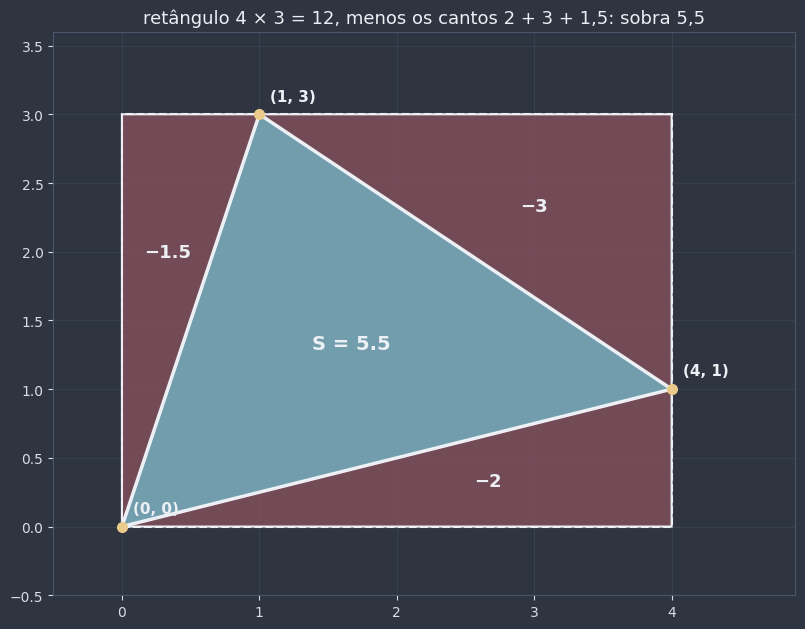

In [14]:
P1, P2, P3 = (0, 0), (4, 1), (1, 3)
cantos = [[(0, 0), (4, 0), (4, 1)], [(4, 1), (4, 3), (1, 3)], [(0, 0), (1, 3), (0, 3)]]
fig, ax = plt.subplots(figsize=(8.5, 6.4))
fig.patch.set_facecolor(NORD_FUNDO)
estilizar_eixo(ax)
desenhar_peca(ax, [(0, 0), (4, 0), (4, 3), (0, 3)], cor=NORD_PAINEL, opacidade=0.4, estilo="--")
for canto in cantos:
    desenhar_peca(ax, canto, cor=COR_SUBTRAIDA, opacidade=0.45,
                  rotulo=f"−{area_triangulo_coordenadas(*canto):g}", tamanho=13)
desenhar_peca(ax, [P1, P2, P3], cor=COR_CIRCULO, opacidade=0.75, largura=2.5,
              rotulo=f"S = {area_triangulo_coordenadas(P1, P2, P3):g}", tamanho=14)
for P in (P1, P2, P3):
    desenhar_ponto(ax, P, f"({P[0]}, {P[1]})", cor=COR_AVISO, deslocamento=(0.08, 0.1), tamanho_fonte=11)
ax.set_xlim(-0.5, 4.9)
ax.set_ylim(-0.5, 3.6)
ax.set_aspect("equal")
ax.set_title("retângulo 4 × 3 = 12, menos os cantos 2 + 3 + 1,5: sobra 5,5", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()
assert iguais(12 - sum(area_triangulo_coordenadas(*c) for c in cantos), 5.5)

### Polígonos quaisquer: triangular e somar

Em [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb), um polígono convexo de $n$ lados foi dividido, a partir de um vértice, em $n - 2$ triângulos. A área do polígono é a **soma** das áreas desses triângulos, e cada uma sai pela fórmula das coordenadas. Para que a mesma receita funcione também em polígonos **côncavos**, basta tirar o módulo $|\ |$ de cada triângulo e guardar o **sinal**: a expressão $x_1(y_2 - y_3) + x_2(y_3 - y_1) + x_3(y_1 - y_2)$ é **positiva** quando os vértices estão no sentido anti-horário e **negativa** no horário. Os triângulos que "saem" do polígono côncavo ficam com o sinal trocado e são **descontados** automaticamente. (Somando os triângulos com sinal, chega-se exatamente à fórmula do cadarço: é por isso que ela funciona.)

terreno: 99.5   ponta de flecha: 12   (iguais ao cadarço; regulares de 3 a 12 lados iguais a p·a)  ✓


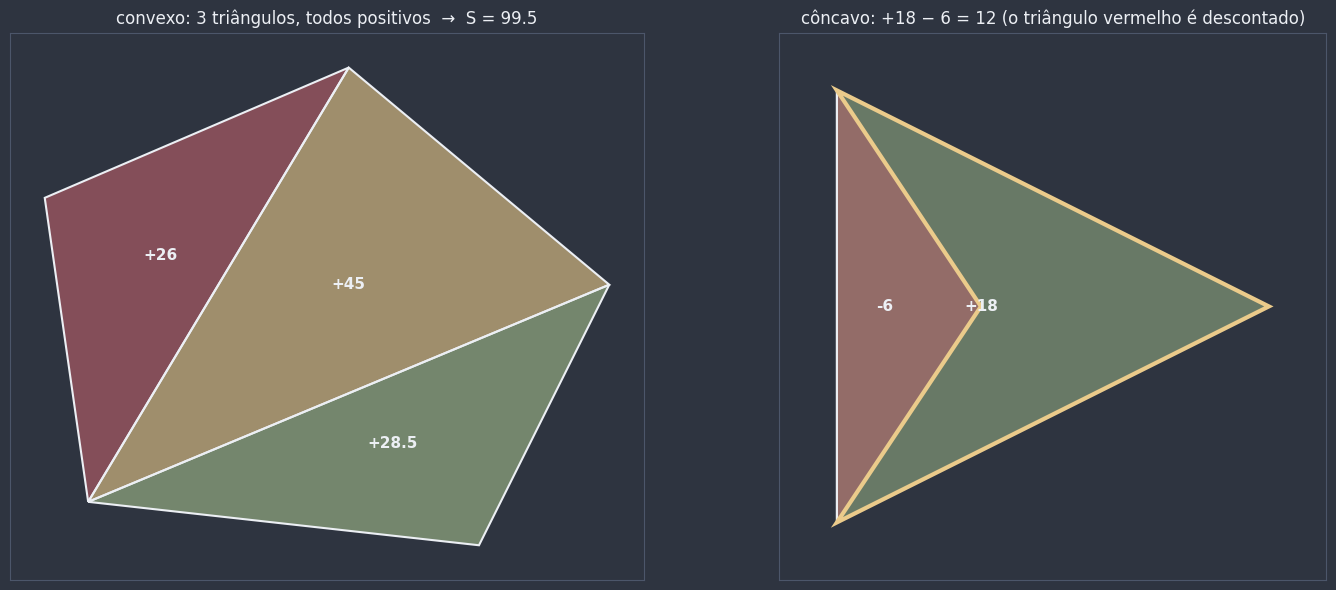

In [15]:
def area_triangulo_orientada(A, B, C) -> float:
    """Área COM SINAL: positiva se A → B → C gira no sentido anti-horário, negativa no horário."""
    (x1, y1), (x2, y2), (x3, y3) = A, B, C
    return (x1 * (y2 - y3) + x2 * (y3 - y1) + x3 * (y1 - y2)) / 2


def area_poligono(vertices) -> float:
    """Área de um polígono simples (convexo ou côncavo): soma, com sinal, dos n − 2 triângulos V₀VₖVₖ₊₁ (0411a)."""
    V = [tuple(v) for v in vertices]
    return abs(sum(area_triangulo_orientada(V[0], V[k], V[k + 1]) for k in range(1, len(V) - 1)))


terreno = [(0, 0), (9, -1), (12, 5), (6, 10), (-1, 7)]  # pentágono convexo
seta = [(0, 0), (6, 3), (0, 6), (2, 3)]  # quadrilátero côncavo (a "ponta de flecha")
assert iguais(area_poligono(terreno), area_cadarco(terreno)) and iguais(area_poligono(seta), area_cadarco(seta))
for n in range(3, 13):
    assert iguais(area_poligono(vertices_regular(n, 2.5)), area_regular(n, 2.5))
print(f"terreno: {area_poligono(terreno):g}   ponta de flecha: {area_poligono(seta):g}   "
      "(iguais ao cadarço; regulares de 3 a 12 lados iguais a p·a)  ✓")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor(NORD_FUNDO)
for k in range(1, len(terreno) - 1):
    tri = [terreno[0], terreno[k], terreno[k + 1]]
    desenhar_peca(ax1, tri, cor=CORES_PECAS[k], opacidade=0.6, rotulo=f"{area_triangulo_orientada(*tri):+g}")
preparar_eixo(ax1, terreno, margem=0.8)
ax1.set_title(f"convexo: 3 triângulos, todos positivos  →  S = {area_poligono(terreno):g}", color=NORD_TEXTO,
              fontsize=12)
for k in range(1, len(seta) - 1):
    tri = [seta[0], seta[k], seta[k + 1]]
    s = area_triangulo_orientada(*tri)
    desenhar_peca(ax2, tri, cor=COR_DESTAQUE if s > 0 else COR_SUBTRAIDA, opacidade=0.5, rotulo=f"{s:+g}")
desenhar_peca(ax2, seta, cor=COR_CIRCULO, opacidade=0.0, largura=3, borda=COR_AVISO)
preparar_eixo(ax2, seta, margem=0.8)
ax2.set_title(f"côncavo: +18 − 6 = {area_poligono(seta):g} (o triângulo vermelho é descontado)", color=NORD_TEXTO,
              fontsize=12)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — o editor de triângulos:** escolha os três lados $a$, $b$ e $c$. O triângulo é construído (se existir: a desigualdade triangular de 0404a precisa valer), com a altura (laranja), a circunferência inscrita (verde) e a circunscrita (roxa). O painel mostra a área pelos cinco caminhos e a **maior diferença** entre eles, que deve ficar perto de zero (só os arredondamentos do computador).

In [ ]:
def triangulo_por_lados(a: float, b: float, c: float):
    """Vértices A, B, C do triângulo de lados a = BC, b = CA, c = AB, com B = (0, 0) e C = (a, 0) (0417a).
    A abscissa de A sai de Pitágoras nos dois triângulos retângulos que a altura forma."""
    x = (a**2 + c**2 - b**2) / (2 * a)
    return np.array([x, math.sqrt(max(c**2 - x**2, 0.0))]), np.array([0.0, 0.0]), np.array([a, 0.0])


def explorar_triangulo(a: float, b: float, c: float) -> None:
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 6.4), gridspec_kw={"width_ratios": [1.1, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    if not (a < b + c and b < a + c and c < a + b):
        escrever_checklist(ax_lista, [(f"{a:g}, {b:g}, {c:g}: não existe triângulo (desigualdade triangular)", False)],
                           "Editor de triângulos")
        preparar_eixo(ax, [(0, 0), (1, 1)])
        plt.tight_layout()
        plt.show()
        return
    A, B, C = triangulo_por_lados(a, b, c)
    I, O = incentro(A, B, C), circuncentro(A, B, C)
    r, R = distancia_ponto_reta(I, B, C), math.dist(O, A)
    desenhar_circunferencia(ax, O, R, cor=COR_TRIANGULO, largura=1.5, estilo="--")
    desenhar_circunferencia(ax, I, r, cor=COR_SEGMENTO, largura=2)
    desenhar_peca(ax, [A, B, C], cor=COR_CIRCULO, opacidade=0.45, largura=2)
    H = pe_da_altura(A, B, C)
    desenhar_segmento(ax, A, H, cor=COR_COROA, largura=2.2, estilo="--")
    for P, nome in ((A, "A"), (B, "B"), (C, "C")):
        desenhar_ponto(ax, P, nome, deslocamento=(0.15, 0.15))
    preparar_eixo(ax, [O - R, O + R, A, B, C], margem=0.5)
    ax.set_title(f"a = {a:g}, b = {b:g}, c = {c:g}", color=NORD_TEXTO, fontsize=13)
    metodos = compara_metodos(A, B, C)
    diferenca = max(metodos.values()) - min(metodos.values())
    itens = [(f"{nome:>12}: S = {valor:.6f}", True) for nome, valor in metodos.items()]
    itens += [(f"p = {semiperimetro(a, b, c):.3f}, r = {r:.3f}, R = {R:.3f}, h_a = {math.dist(A, H):.3f}", True),
              (f"maior diferença entre os caminhos: {diferenca:.1e}", diferenca < 1e-9 * max(1, metodos['Herão']))]
    escrever_checklist(ax_lista, itens, "Cinco caminhos, uma área")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_triangulo,
                 a=widgets.FloatSlider(value=14, min=1, max=20, step=0.5, description="a:"),
                 b=widgets.FloatSlider(value=15, min=1, max=20, step=0.5, description="b:"),
                 c=widgets.FloatSlider(value=13, min=1, max=20, step=0.5, description="c:"));

interactive(children=(FloatSlider(value=14.0, description='a:', max=20.0, min=1.0, step=0.5), FloatSlider(valu…

🕹️ **Widget interativo — "o que o enunciado me deu?":** escolha os dados disponíveis. A célula mostra a fórmula mais direta, por que ela é a escolha natural e um exemplo resolvido com as funções do notebook.

In [ ]:
ESCOLHAS = {
    "base e altura": ("S = b·h/2", "é a definição; não precisa de mais nada",
                      "b = 10, h = 7", lambda: area_triangulo(base=10, altura=7)),
    "os três lados": ("Herão: S = √[p(p − a)(p − b)(p − c)]", "vai direto dos lados para a área, sem achar a altura",
                      "lados 13, 14, 15", lambda: area_triangulo(lados=(13, 14, 15))),
    "lados e raio inscrito": ("S = p·r", "o raio inscrito é a altura de cada um dos três triângulos com vértice no incentro",
                              "lados 5, 5, 6 e r = 1,5", lambda: area_triangulo(lados=(5, 5, 6), raio_inscrito=1.5)),
    "lados e raio circunscrito": ("S = abc/(4R)", "liga a área à circunferência que passa pelos vértices",
                                  "lados 13, 14, 15 e R = 8,125",
                                  lambda: area_triangulo(lados=(13, 14, 15), raio_circunscrito=8.125)),
    "dois catetos": ("S = b·c/2", "num triângulo retângulo, um cateto é a altura relativa ao outro",
                     "catetos 9 e 12", lambda: area_triangulo(catetos=(9, 12))),
    "lado do equilátero": ("S = ℓ²√3/4", "a altura do equilátero é ℓ√3/2 (Pitágoras)",
                           "ℓ = 6", lambda: area_triangulo(lado_equilatero=6)),
    "coordenadas dos vértices": ("S = ½|x₁(y₂ − y₃) + x₂(y₃ − y₁) + x₃(y₁ − y₂)|", "não precisa de lados nem de ângulos",
                                 "(0, 0), (4, 1), (1, 3)", lambda: area_triangulo(vertices=((0, 0), (4, 1), (1, 3)))),
    "polígono regular": ("S = p·a", "o regular é n triângulos congruentes de altura a",
                         "hexágono regular de lado 4 (R = 4)", lambda: area_regular(6, 4)),
    "polígono irregular": ("triangular (n − 2 triângulos) e somar", "toda região poligonal se decompõe em triângulos",
                           "o terreno de 5 vértices", lambda: area_poligono(terreno)),
}


def explorar_escolha(dados: str) -> None:
    formula, motivo, exemplo, conta = ESCOLHAS[dados]
    display(Markdown(f"**Dados:** {dados}  \n**Fórmula mais direta:** {formula}  \n**Por quê:** {motivo}.  \n"
                     f"**Exemplo:** {exemplo} ⇒ $S \\approx$ **{conta():.4f}**"))


widgets.interact(explorar_escolha, dados=widgets.Dropdown(options=list(ESCOLHAS), value="os três lados",
                                                          description="dados:"));

interactive(children=(Dropdown(description='dados:', index=1, options=('base e altura', 'os três lados', 'lado…

🎯 **Aplicação prática — construção civil e topografia:** para saber quanto piso comprar, decompõe-se a planta em retângulos e triângulos; para medir um **terreno**, o topógrafo marca os vértices e usa **triangulação** ou as **coordenadas** (com GPS, as coordenadas saem direto). O terreno triangular de 13, 14 e 15 m de [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) tem 84 m² por qualquer um dos caminhos.

⚠️ **Erro comum: usar um lado inclinado como "altura".** No trapézio, no paralelogramo e no triângulo, a altura é a distância **perpendicular** ([`0407a_perpendicularidade.ipynb`](0407a_perpendicularidade.ipynb)), não o comprimento do lado oblíquo.

⚠️ **Erro comum: aplicar Herão com o perímetro em vez do semiperímetro.** Com lados 3, 4, 5, $p = 6$ dá $\sqrt{6 \cdot 3 \cdot 2 \cdot 1} = 6$ (certo); com 12 no lugar de $p$, sai $\sqrt{12 \cdot 9 \cdot 8 \cdot 7}$, um absurdo.

⚠️ **Erro comum: usar $\frac{b \cdot h}{2}$ conhecendo dois lados, mas não a altura.** Se o enunciado dá os lados, o caminho é Herão (ou achar a altura antes, por Pitágoras).

⚠️ **Erro comum: esquecer o $\frac{1}{2}$ do losango e do trapézio** (o losango é **metade** do retângulo das diagonais; o trapézio é a base **média** vezes a altura).

**Pergunta de checagem:** qual é a área de um triângulo de lados 5, 5 e 6? Qual é o raio da circunferência inscrita? E o da circunscrita?

**Pergunta de checagem:** qual é a área do triângulo de vértices $(0, 0)$, $(4, 1)$ e $(1, 3)$, e qual seria a fórmula mais direta se, em vez das coordenadas, o enunciado desse os três lados?

## 4. Regiões compostas e sombreadas

A maioria dos problemas de verdade (e de prova) não traz uma figura "de catálogo", e sim uma **região composta**: um pedaço de círculo colado num retângulo, um quadrado com um furo, a parte comum de dois círculos. Não existe fórmula pronta para cada uma; existe um **método**. São cinco estratégias:

1. **Soma:** dividir em figuras conhecidas e somar. Uma pista de atletismo é um **retângulo + dois semicírculos**; uma planta em "L" é **dois retângulos**.
2. **Subtração:** da figura grande, retirar o que não pertence. Uma moldura é **quadrado − quadrado**; a coroa é **círculo − círculo**; uma chapa com furo é **quadrado − círculo**.
3. **Simetria:** calcular uma parte e multiplicar (um padrão com quatro "pétalas" iguais).
4. **Reorganização:** deslocar pedaços (a equivalência de 0419a); é o caso das lúnulas de Hipócrates.
5. **Proporção:** usar a razão $k^2$ entre partes semelhantes.

💡 **Dica:** antes de calcular, **escreva a decomposição em palavras** ("quadrado menos quatro quartos de círculo"). Se a decomposição está certa, as contas são mecânicas.

### Exemplos guiados

**A pétala.** Num quadrado de lado $\ell$, desenhe dois quartos de círculo de raio $\ell$, com centros em dois vértices **opostos**. A região comum aos dois é a "pétala". Os dois quartos de círculo, juntos, medem $2 \cdot \frac{\pi \ell^2}{4} = \frac{\pi \ell^2}{2}$; eles **cobrem o quadrado inteiro**, e a pétala é coberta **duas vezes**. Pela aditividade (0419a): $\frac{\pi \ell^2}{2} = \ell^2 + S_{pétala}$, logo

$$S_{pétala} = \left(\frac{\pi}{2} - 1\right)\ell^2 \approx 0{,}5708\,\ell^2.$$

**O triângulo de Reuleaux.** É o "triângulo arredondado" formado por três arcos de raio $\ell$, cada um centrado num vértice de um triângulo equilátero de lado $\ell$. Ele é a **união de três setores de 60°** (um em cada vértice); os três setores se sobrepõem no triângulo, que é contado **três** vezes em vez de uma. Então: três setores menos **duas** vezes o triângulo,

$$S_{Reuleaux} = 3 \cdot \frac{\pi \ell^2}{6} - 2 \cdot \frac{\ell^2\sqrt{3}}{4} = \frac{(\pi - \sqrt{3})\,\ell^2}{2} \approx 0{,}7048\,\ell^2.$$

(Outro jeito de ver: o triângulo equilátero mais três segmentos circulares de 60°.)

**As lúnulas de Hipócrates (agora com $\pi$).** Num triângulo retângulo de catetos $b$ e $c$ e hipotenusa $a$, desenhe semicírculos para fora sobre os dois catetos e o semicírculo sobre a hipotenusa que passa pelo vértice do ângulo reto (0413a: o ângulo inscrito numa semicircunferência é reto). As duas "luas" que ficam fora do semicírculo grande são as **lúnulas**. Somando o triângulo e os dois semicírculos pequenos e tirando o semicírculo grande:

$$S_{lúnulas} = \frac{\pi b^2}{8} + \frac{\pi c^2}{8} + \frac{bc}{2} - \frac{\pi a^2}{8} = \frac{bc}{2} + \frac{\pi}{8}\underbrace{(b^2 + c^2 - a^2)}_{= 0 \text{ (Pitágoras)}} = \frac{bc}{2}.$$

**O $\pi$ cancela!** As duas lúnulas têm, juntas, exatamente a área do triângulo. Em 0419a isso saiu da razão $k^2$, sem fórmula de círculo; aqui, a conta com $\pi$ mostra o cancelamento acontecendo.

**Hexágono dentro do círculo.** O hexágono regular inscrito num círculo de raio $R$ tem área $\frac{3\sqrt{3}}{2}R^2$, e a razão $\frac{3\sqrt{3}/2}{\pi} \approx 0{,}827$: o hexágono ocupa **82,7%** do círculo (por isso favos de mel e parafusos sextavados "aproveitam" tão bem o espaço, como no ladrilhamento de 0418a).

📌 **Definição formal:** estratégias **soma, subtração, simetria, reorganização, proporção**; $S_{pétala} = \left(\frac{\pi}{2} - 1\right)\ell^2$; $S_{Reuleaux} = \frac{(\pi - \sqrt{3})\ell^2}{2}$; lúnulas de Hipócrates $= \frac{bc}{2}$.

Na célula abaixo, cada região é **construída como polígono** (centenas de pontos sobre cada arco) e medida pela régua de área. O valor da fórmula e o valor medido devem coincidir em várias casas decimais. Lembre que a conferência numérica **ilustra**; quem **garante** é a dedução acima.

In [18]:
def area_petala(l: float) -> float:
    """Região comum a dois quartos de círculo de raio l centrados em vértices opostos do quadrado de lado l."""
    return (math.pi / 2 - 1) * l**2


def area_reuleaux(l: float) -> float:
    """Triângulo de Reuleaux de largura l: três setores de 60° menos duas vezes o equilátero."""
    return 3 * area_setor(l, 60) - 2 * area_triangulo(lado_equilatero=l)


def area_lunulas(b: float, c: float) -> float:
    """Soma das duas lúnulas de Hipócrates do triângulo retângulo de catetos b e c:
    semicírculos dos catetos + triângulo − semicírculo da hipotenusa."""
    a = math.hypot(b, c)
    return math.pi * b**2 / 8 + math.pi * c**2 / 8 + b * c / 2 - math.pi * a**2 / 8


def area_pista(comprimento: float, largura: float) -> float:
    """Pista de atletismo: retângulo comprimento × largura + dois semicírculos de diâmetro igual à largura."""
    return comprimento * largura + area_circulo(largura / 2)


# As mesmas regiões, construídas como polígonos de muitos lados (para desenhar e medir com a régua)
def petala_pontos(l: float, n: int = 2000) -> np.ndarray:
    return np.vstack([pontos_arco((0, 0), l, 0, 90, n), pontos_arco((l, l), l, 180, 270, n)])


def reuleaux_pontos(l: float, n: int = 2000) -> np.ndarray:
    P0, P1, P2 = np.array([0.0, 0.0]), np.array([l, 0.0]), np.array([l / 2, l * math.sqrt(3) / 2])
    return np.vstack([pontos_arco(P2, l, 240, 300, n), pontos_arco(P0, l, 0, 60, n), pontos_arco(P1, l, 120, 180, n)])


def lunula_pontos(b: float, c: float, cateto: str, n: int = 2000) -> np.ndarray:
    """Lúnula sobre o cateto AB (horizontal, 'c') ou AC (vertical, 'b') do triângulo A = (0, 0), B = (c, 0),
    C = (0, b): o arco do semicírculo pequeno (para fora) e, de volta, o arco do semicírculo grande."""
    A, B, C = np.array([0.0, 0.0]), np.array([c, 0.0]), np.array([0.0, b])
    M, a = ponto_medio(B, C), math.hypot(b, c)  # centro e diâmetro da circunferência da hipotenusa
    if cateto == "c":  # sobre AB: semicírculo pequeno por baixo, de A até B; volta de B até A pelo arco grande
        pequeno = pontos_arco(ponto_medio(A, B), c / 2, 180, 360, n)
        grande = pontos_arco(M, a / 2, direcao_de(M, B), direcao_de(M, A), n)
    else:  # sobre AC: semicírculo pequeno pela esquerda, de C até A; volta de A até C pelo arco grande
        pequeno = pontos_arco(ponto_medio(C, A), b / 2, 90, 270, n)
        grande = pontos_arco(M, a / 2, direcao_de(M, A) % 360, direcao_de(M, C) % 360, n)
    return np.vstack([pequeno, grande])


def pista_pontos(comprimento: float, largura: float, n: int = 2000) -> np.ndarray:
    rho = largura / 2
    return np.vstack([pontos_arco((comprimento, rho), rho, -90, 90, n), pontos_arco((0, rho), rho, 90, 270, n)])


linhas = []
for l in (1, 2.5):
    linhas.append({"região": f"pétala (ℓ = {l:g})", "fórmula": area_petala(l), "régua": area_cadarco(petala_pontos(l))})
    linhas.append({"região": f"Reuleaux (ℓ = {l:g})", "fórmula": area_reuleaux(l),
                   "régua": area_cadarco(reuleaux_pontos(l))})
for b, c in ((3, 4), (1, 1), (5, 12)):
    soma = area_cadarco(lunula_pontos(b, c, "b")) + area_cadarco(lunula_pontos(b, c, "c"))
    linhas.append({"região": f"lúnulas (catetos {b} e {c})", "fórmula": area_lunulas(b, c), "régua": soma})
linhas.append({"região": "pista 100 × 60", "fórmula": area_pista(100, 60), "régua": area_cadarco(pista_pontos(100, 60))})
linhas.append({"região": "moldura: quadrado 20 com furo de raio 6", "fórmula": 20**2 - area_circulo(6),
               "régua": 20**2 - area_cadarco(regiao_circulo((10, 10), 6, 4000))})
linhas.append({"região": "hexágono / círculo (R = 1)", "fórmula": 3 * math.sqrt(3) / 2 / math.pi,
               "régua": area_cadarco(vertices_regular(6, 1)) / area_cadarco(regiao_circulo((0, 0), 1, 4000))})
tabela_compostas = pd.DataFrame(linhas)
tabela_compostas["diferença"] = (tabela_compostas["fórmula"] - tabela_compostas["régua"]).abs()
display(tabela_compostas.round(6))
assert (tabela_compostas["diferença"] < 1e-4 * tabela_compostas["fórmula"].abs().clip(lower=1)).all()
for b, c in ((3, 4), (1, 1), (5, 12), (0.5, 7)):
    assert iguais(area_lunulas(b, c), b * c / 2)
assert iguais(area_petala(1), math.pi / 2 - 1) and iguais(area_reuleaux(1), (math.pi - math.sqrt(3)) / 2)
print("Fórmula e régua concordam em todas as regiões; as lúnulas valem sempre bc/2 (o π cancela).  ✓")

,região,fórmula,régua,diferença
0,pétala (ℓ = 1),0.570796,0.570796,0.000000
1,Reuleaux (ℓ = 1),0.704771,0.704771,0.000000
2,pétala (ℓ = 2.5),3.567477,3.567476,0.000001
3,Reuleaux (ℓ = 2.5),4.404818,4.404818,0.000000
4,lúnulas (catetos 3 e 4),6.000000,5.999997,0.000003
5,lúnulas (catetos 1 e 1),0.500000,0.500000,0.000000
6,lúnulas (catetos 5 e 12),30.000000,29.999985,0.000015
7,pista 100 × 60,8827.433388,8827.432225,0.001163
8,moldura: quadrado 20 com furo de raio 6,286.902664,286.902711,0.000047
9,hexágono / círculo (R = 1),0.826993,0.826994,0.000000


Fórmula e régua concordam em todas as regiões; as lúnulas valem sempre bc/2 (o π cancela).  ✓


A representação gráfica das decomposições, com as cores do notebook: o que é **somado** aparece em tons frios ou amarelo, o que é **subtraído** em vermelho, e a região procurada em **verde**.

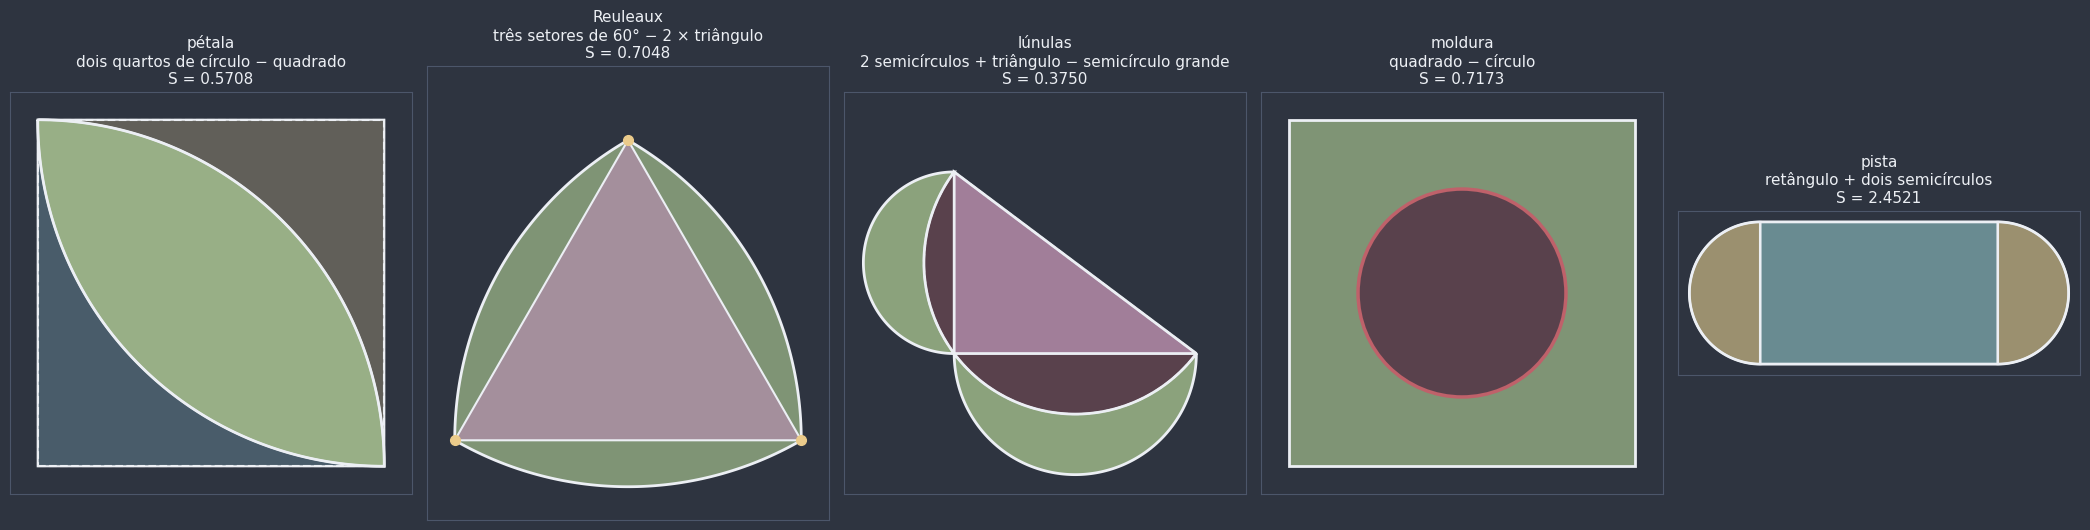

In [19]:
def desenhar_composta(ax, figura: str, tamanho: float = 1.0) -> tuple[float, float]:
    """Desenha a região composta com a sua decomposição; devolve (área pela fórmula, área pela régua)."""
    l = tamanho
    if figura == "pétala":
        desenhar_peca(ax, [(0, 0), (l, 0), (l, l), (0, l)], cor=NORD_PAINEL, opacidade=0.5, estilo="--")
        desenhar_peca(ax, np.vstack([[(0, 0)], pontos_arco((0, 0), l, 0, 90)]), cor=COR_CIRCULO, opacidade=0.25)
        desenhar_peca(ax, np.vstack([[(l, l)], pontos_arco((l, l), l, 180, 270)]), cor=COR_SETOR, opacidade=0.25)
        desenhar_peca(ax, petala_pontos(l, 300), cor=COR_SEGMENTO, opacidade=0.8, largura=2)
        preparar_eixo(ax, [(0, 0), (l, l)], margem=0.08 * l)
        return area_petala(l), area_cadarco(petala_pontos(l))
    if figura == "Reuleaux":
        P = [(0, 0), (l, 0), (l / 2, l * math.sqrt(3) / 2)]
        desenhar_peca(ax, reuleaux_pontos(l, 300), cor=COR_SEGMENTO, opacidade=0.7, largura=2)
        desenhar_peca(ax, P, cor=COR_TRIANGULO, opacidade=0.7)
        for v in P:
            desenhar_ponto(ax, v, cor=COR_AVISO)
        preparar_eixo(ax, [(0, -0.15 * l), (l, l)], margem=0.08 * l)
        return area_reuleaux(l), area_cadarco(reuleaux_pontos(l))
    if figura == "lúnulas":
        b, c = 3 * l / 4, l  # catetos na proporção 3 : 4
        A, B, C = (0, 0), (c, 0), (0, b)
        M, a = ponto_medio(B, C), math.hypot(b, c)
        # O semicírculo da hipotenusa que passa por A (é ele que é subtraído)
        desenhar_peca(ax, pontos_arco(M, a / 2, direcao_de(M, B) - 180, direcao_de(M, B), 300),
                      cor=COR_SUBTRAIDA, opacidade=0.3, estilo="--")
        for qual in ("b", "c"):
            desenhar_peca(ax, lunula_pontos(b, c, qual, 300), cor=COR_SEGMENTO, opacidade=0.8, largura=2)
        desenhar_peca(ax, [A, B, C], cor=COR_TRIANGULO, opacidade=0.8, largura=2)
        preparar_eixo(ax, [(-b / 2, -c / 2), (c, b + 0.1 * l), M + a / 2], margem=0.08 * l)
        soma = area_cadarco(lunula_pontos(b, c, "b")) + area_cadarco(lunula_pontos(b, c, "c"))
        return area_lunulas(b, c), soma
    if figura == "moldura":
        desenhar_peca(ax, [(0, 0), (l, 0), (l, l), (0, l)], cor=COR_SEGMENTO, opacidade=0.7, largura=2)
        ax.add_patch(Circle((l / 2, l / 2), 0.3 * l, facecolor=NORD_FUNDO, edgecolor=COR_SUBTRAIDA, lw=2.5, zorder=6))
        ax.add_patch(Circle((l / 2, l / 2), 0.3 * l, facecolor=COR_SUBTRAIDA, alpha=0.3, zorder=7))
        preparar_eixo(ax, [(0, 0), (l, l)], margem=0.08 * l)
        return l**2 - area_circulo(0.3 * l), l**2 - area_cadarco(regiao_circulo((l / 2, l / 2), 0.3 * l, 4000))
    # pista: retângulo + dois semicírculos (comprimento 5/3 da largura, como 100 × 60)
    comprimento, largura = 5 * l / 3, l
    desenhar_peca(ax, pista_pontos(comprimento, largura, 300), cor=COR_SEGMENTO, opacidade=0.25, largura=2)
    desenhar_peca(ax, [(0, 0), (comprimento, 0), (comprimento, largura), (0, largura)], cor=COR_CIRCULO, opacidade=0.5)
    for centro, (ini, fim) in (((comprimento, largura / 2), (-90, 90)), ((0, largura / 2), (90, 270))):
        desenhar_peca(ax, pontos_arco(centro, largura / 2, ini, fim, 300), cor=COR_SETOR, opacidade=0.5)
    preparar_eixo(ax, [(-largura / 2, 0), (comprimento + largura / 2, largura)], margem=0.08 * l)
    return area_pista(comprimento, largura), area_cadarco(pista_pontos(comprimento, largura))


DECOMPOSICOES = {
    "pétala": "dois quartos de círculo − quadrado",
    "Reuleaux": "três setores de 60° − 2 × triângulo",
    "lúnulas": "2 semicírculos + triângulo − semicírculo grande",
    "moldura": "quadrado − círculo",
    "pista": "retângulo + dois semicírculos",
}
fig, eixos = plt.subplots(1, 5, figsize=(21, 5.2))
fig.patch.set_facecolor(NORD_FUNDO)
for ax, figura in zip(eixos, DECOMPOSICOES):
    formula, regua = desenhar_composta(ax, figura, 1.0)
    ax.set_title(f"{figura}\n{DECOMPOSICOES[figura]}\nS = {formula:.4f}", color=NORD_TEXTO, fontsize=11)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — regiões compostas:** escolha a figura e o tamanho (o lado do quadrado, o lado do triângulo de Reuleaux, o cateto maior das lúnulas, a largura da pista). O painel mostra a decomposição em palavras, a área pela fórmula e pela régua, e a razão entre a área e o tamanho ao quadrado, que **não muda** quando o tamanho muda (a razão $k^2$ outra vez).

In [ ]:
def explorar_composta(figura: str, tamanho: float) -> None:
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    formula, regua = desenhar_composta(ax, figura, tamanho)
    ax.set_title(f"{figura}, tamanho {tamanho:g}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"decomposição: {DECOMPOSICOES[figura]}", True),
        (f"área pela fórmula: {formula:.6f}", True),
        (f"área pela régua (polígono de muitos lados): {regua:.6f}", abs(formula - regua) < 1e-4 * max(1, formula)),
        (f"diferença: {abs(formula - regua):.1e}", True),
        (f"área / tamanho² = {formula / tamanho**2:.6f} (não depende do tamanho)", True),
    ]
    escrever_checklist(ax_lista, itens, "Fórmula × régua de área")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_composta,
                 figura=widgets.Dropdown(options=list(DECOMPOSICOES), value="pétala", description="figura:"),
                 tamanho=widgets.FloatSlider(value=10, min=1, max=20, step=1, description="tamanho:"));

interactive(children=(Dropdown(description='figura:', options=('pétala', 'Reuleaux', 'lúnulas', 'moldura', 'pi…

🎯 **Aplicação prática — paisagismo, arquitetura e arte:** canteiros com bordas curvas, pistas de atletismo, plantas com cômodos em "L" e janelas em arco são todos regiões compostas. A pétala e as **rosáceas** de vitrais góticos são feitas de arcos de mesmo raio; o triângulo de Reuleaux aparece em tampas de bueiro e em brocas que fazem furos "quase quadrados", justamente por ter **largura constante** (como o círculo, ele rola entre duas paralelas sem que a distância entre elas mude).

🕵️ **Curiosidade histórica:** a figura leva o nome do engenheiro alemão **Franz Reuleaux** (século XIX), que estudou formas de largura constante em máquinas, embora curvas parecidas já apareçam em desenhos bem mais antigos. As lúnulas são atribuídas a **Hipócrates de Quios** (século V a.C.), considerado um dos primeiros a calcular exatamente a área de uma região limitada por curvas.

⚠️ **Erro comum: procurar uma fórmula pronta para a região sombreada.** A região sombreada quase nunca é "uma figura só"; ela é soma e diferença de figuras conhecidas. Escreva a decomposição primeiro.

⚠️ **Erro comum: contar duas vezes (ou nenhuma) a parte em que duas figuras se sobrepõem.** Na pétala e no Reuleaux, o segredo está em perceber **quantas vezes** cada pedaço foi coberto.

📖 **Leitura complementar:** [Triângulo de Reuleaux](https://pt.wikipedia.org/wiki/Tri%C3%A2ngulo_de_Reuleaux) (largura constante e construções; a área foi deduzida aqui)

**Pergunta de checagem:** num quadrado de lado 10, dois quartos de círculo de raio 10 centrados em vértices opostos se cruzam. Qual é a área da região comum? E a área do triângulo de Reuleaux de lado 2?

**Pergunta de checagem:** um quadrado de lado 10 tem, em cada canto, um quarto de círculo de raio 5 recortado. Escreva a decomposição em palavras e calcule a área que sobra.

## 5. Escala, unidades, probabilidade geométrica e Monte Carlo

### 5.1 Escala e $k^2$

📎 Prometido em [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb): num mapa ou numa planta na escala $1 : n$, cada **comprimento** real vale $n$ vezes o do desenho, e cada **área** real vale $n^2$ vezes a do desenho (a razão $k^2$ de 0419a, com $k = n$).

Exemplo: numa planta na escala $1 : 50$, um cômodo mede $4 \text{ cm} \times 6 \text{ cm}$ (24 cm² no papel). Na realidade, os lados medem $4 \cdot 50 = 200$ cm $= 2$ m e $6 \cdot 50 = 300$ cm $= 3$ m, e a área é $6$ m². Pela regra: $24 \cdot 50^2 = 60\,000$ cm² $= 6$ m². **Dobrar** o tamanho quadruplica a área; **triplicar** multiplica por 9.

### 5.2 Unidades de área

Um metro tem 100 centímetros, então um **metro quadrado** é um quadrado de $100 \text{ cm} \times 100 \text{ cm}$:

$$1 \text{ m}^2 = 10\,000 \text{ cm}^2 \quad (\text{e não } 100!).$$

Do mesmo jeito, $1 \text{ km}^2 = 1\,000\,000 \text{ m}^2$. No campo, usa-se o **hectare**: $1 \text{ ha} = 10\,000 \text{ m}^2$ (um quadrado de 100 m de lado, quase um campo de futebol e meio), e $1 \text{ km}^2 = 100 \text{ ha}$. No Brasil aparece também o **alqueire**, que **não é uniforme**: o alqueire paulista tem $24\,200$ m² e o mineiro tem $48\,400$ m² (há outros valores regionais). Antes de comprar um terreno "em alqueires", pergunte qual alqueire!

### 5.3 Custo e consumo

Quase todo orçamento de obra é **área × preço por unidade de área**: piso (R\$/m²), pintura (m² por litro de tinta), grama, telhado. Na prática, compra-se uma **sobra** para cortes e perdas, em geral cerca de 10%: área a comprar $=$ área $\times 1{,}10$.

In [21]:
def area_real(area_desenho: float, escala: float) -> float:
    """Área real a partir da área no desenho, numa escala 1 : escala (mesma unidade, ao quadrado)."""
    return area_desenho * escala**2


def custo_piso(area: float, preco: float, perda: float = 0.10) -> float:
    """Custo do piso: área × (1 + perda) × preço por unidade de área."""
    return area * (1 + perda) * preco


UNIDADES_M2 = {"cm²": 1e-4, "m²": 1.0, "hectare (ha)": 1e4, "km²": 1e6, "alqueire paulista": 24_200.0,
               "alqueire mineiro": 48_400.0}


def converter_area(valor: float, de: str, para: str) -> float:
    """Converte uma área entre as unidades de UNIDADES_M2 (passando pelo m²)."""
    return valor * UNIDADES_M2[de] / UNIDADES_M2[para]


# A planta 1 : 50
papel = 4 * 6  # cm²
real_cm2 = area_real(papel, 50)
print(f"planta 1:50 — no papel {papel} cm², na realidade {real_cm2:,.0f} cm² = {converter_area(real_cm2, 'cm²', 'm²'):g} m²")
assert iguais(converter_area(real_cm2, "cm²", "m²"), 2 * 3)

display(pd.DataFrame(
    [{"1 unidade de": u, **{v: converter_area(1, u, v) for v in ("m²", "hectare (ha)", "km²")}} for u in UNIDADES_M2]
).set_index("1 unidade de"))
assert converter_area(1, "m²", "cm²") == 10_000 and converter_area(1, "km²", "hectare (ha)") == 100

# Piso para uma sala de 4 m × 5 m a R$ 60,00 o m², com 10% de perda
print(f"sala 4 × 5: compra-se {20 * 1.1:g} m² de piso, custo R$ {custo_piso(20, 60):.2f}")
assert iguais(custo_piso(20, 60), 1320)

planta 1:50 — no papel 24 cm², na realidade 60,000 cm² = 6 m²


,m²,hectare (ha),km²
1 unidade de,,,
cm²,0.0001,1.000000e-08,1.000000e-10
m²,1.0000,1.000000e-04,1.000000e-06
hectare (ha),10000.0000,1.000000e+00,1.000000e-02
km²,1000000.0000,1.000000e+02,1.000000e+00
alqueire paulista,24200.0000,2.420000e+00,2.420000e-02
alqueire mineiro,48400.0000,4.840000e+00,4.840000e-02


sala 4 × 5: compra-se 22 m² de piso, custo R$ 1320.00


### 5.4 Probabilidade geométrica

Quando um ponto cai "ao acaso" numa região, **sem preferência** por nenhuma parte dela, a chance de ele cair numa parte é a **fração da área** que essa parte ocupa:

$$P = \frac{A_{favorável}}{A_{total}}.$$

Foi assim que resolvemos o alvo de dardos ($\frac{1}{9}$, $\frac{3}{9}$, $\frac{5}{9}$). Um exemplo clássico, em que a "região" nem é um desenho:

**O encontro.** Dois amigos combinam de se encontrar entre 12h e 13h. Cada um chega num instante qualquer desse intervalo e espera **15 minutos** pelo outro; se o outro não aparecer, vai embora. Qual é a chance de se encontrarem?

Represente a chegada do primeiro por $x$ e a do segundo por $y$, em minutos depois do meio-dia: cada par $(x, y)$ é um ponto do quadrado $60 \times 60$ (área 3 600). Eles se encontram quando $|x - y| \leq 15$: uma **faixa** em volta da diagonal. Fora da faixa ficam dois triângulos retângulos de catetos $45$, de área total $45^2 = 2\,025$. Então

$$P = \frac{3\,600 - 2\,025}{3\,600} = 1 - \left(\frac{45}{60}\right)^2 = \frac{7}{16} \approx 0{,}44.$$

📎 Conexão: a probabilidade será tratada com calma no módulo de **Análise Combinatória e Probabilidade**; a ideia "probabilidade = razão de áreas" é a porta de entrada da probabilidade **contínua**.

A célula abaixo confere as duas respostas **por simulação**: sorteia muitos dardos e muitos pares de horários e conta os sucessos.

,região,exato,simulado
0,centro,0.1111,0.1117
1,anel do meio,0.3333,0.3342
2,anel de fora,0.5556,0.5542


encontro: exato 7/16 = 0.4375   simulado com 200,000 pares = 0.4366


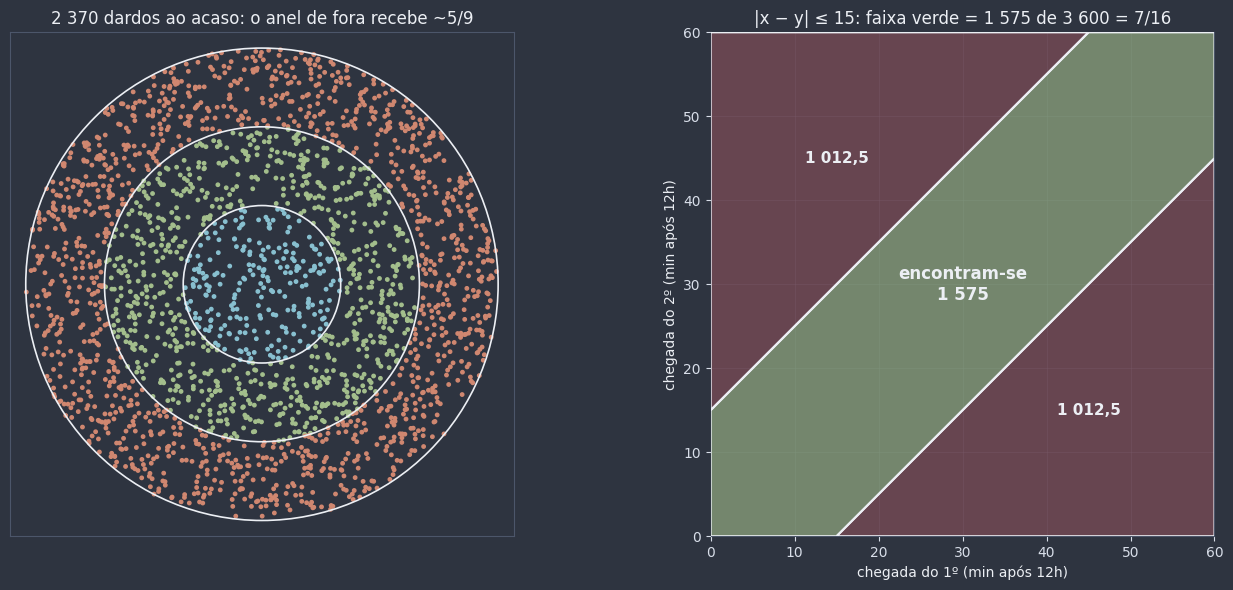

In [22]:
def prob_geometrica(area_favoravel: float, area_total: float) -> float:
    """Probabilidade geométrica: área favorável / área total."""
    return area_favoravel / area_total


gerador = np.random.default_rng(2020)
N = 200_000

# Dardos uniformes no alvo de raio 3: sorteia no quadrado [−3, 3]² e descarta os que caem fora do alvo
x, y = gerador.uniform(-3, 3, (2, N))
distancia = np.hypot(x, y)[np.hypot(x, y) <= 3]
simulado = [np.mean(distancia <= 1), np.mean((distancia > 1) & (distancia <= 2)), np.mean(distancia > 2)]
exato = [prob_geometrica(area_coroa(n, n - 1), area_circulo(3)) for n in (1, 2, 3)]
display(pd.DataFrame({"região": ["centro", "anel do meio", "anel de fora"], "exato": exato, "simulado": simulado}).round(4))

# O encontro
chegadas = gerador.uniform(0, 60, (2, N))
p_simulado = np.mean(np.abs(chegadas[0] - chegadas[1]) <= 15)
p_exato = prob_geometrica(60**2 - 45**2, 60**2)
print(f"encontro: exato 7/16 = {p_exato:.4f}   simulado com {N:,} pares = {p_simulado:.4f}")
assert iguais(p_exato, 7 / 16) and abs(p_simulado - p_exato) < 0.01
assert all(abs(s - e) < 0.01 for s, e in zip(simulado, exato))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor(NORD_FUNDO)
amostra = gerador.uniform(-3, 3, (2, 3000))
amostra = amostra[:, np.hypot(*amostra) <= 3]
cores = np.where(np.hypot(*amostra) <= 1, COR_CIRCULO, np.where(np.hypot(*amostra) <= 2, COR_SEGMENTO, COR_COROA))
ax1.scatter(*amostra, s=6, c=cores)
for r in (1, 2, 3):
    desenhar_circunferencia(ax1, (0, 0), r, cor=NORD_TEXTO, largura=1.2)
preparar_eixo(ax1, [(-3, -3), (3, 3)], margem=0.2)
ax1.set_title(f"{amostra.shape[1]:,} dardos ao acaso: o anel de fora recebe ~5/9".replace(",", " "),
              color=NORD_TEXTO, fontsize=12)
estilizar_eixo(ax2)
desenhar_peca(ax2, [(0, 0), (15, 0), (60, 45), (60, 60), (45, 60), (0, 15)], cor=COR_SEGMENTO, opacidade=0.6,
              rotulo="encontram-se\n1 575", tamanho=12)
desenhar_peca(ax2, [(15, 0), (60, 0), (60, 45)], cor=COR_SUBTRAIDA, opacidade=0.4, rotulo="1 012,5")
desenhar_peca(ax2, [(0, 15), (45, 60), (0, 60)], cor=COR_SUBTRAIDA, opacidade=0.4, rotulo="1 012,5")
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 60)
ax2.set_aspect("equal")
ax2.set_xlabel("chegada do 1º (min após 12h)", color=NORD_TEXTO)
ax2.set_ylabel("chegada do 2º (min após 12h)", color=NORD_TEXTO)
ax2.set_title("|x − y| ≤ 15: faixa verde = 1 575 de 3 600 = 7/16", color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

### 5.5 Monte Carlo: medir áreas por sorteio

A simulação acima pode ser usada **ao contrário**: em vez de conhecer a área e prever a frequência, **medimos a frequência para descobrir a área**. É o **método de Monte Carlo**:

1. envolva a região num retângulo (ou quadrado) de área conhecida $A_{caixa}$;
2. sorteie $N$ pontos uniformemente na caixa e conte quantos caem **dentro** da região;
3. a área estimada é $\text{(fração dentro)} \times A_{caixa}$.

Aplicado ao círculo de raio 1 dentro do quadrado $[-1, 1]^2$ (área 4), a fração esperada é $\frac{\pi}{4}$, e o método **estima $\pi$**: é o **terceiro olhar** para a área do círculo, depois dos polígonos e da cebola. A grande vantagem: ele funciona até para regiões **sem fórmula**, como o "quadrado arredondado" $x^4 + y^4 \leq 1$, que conferimos com a régua de área (a sua borda é $y = \pm\sqrt[4]{1 - x^4}$, sem nenhum seno ou cosseno).

A grande desvantagem: o erro típico cai só como $\frac{1}{\sqrt{N}}$. Para ganhar **uma** casa decimal (erro 10 vezes menor), são precisos **100 vezes** mais pontos. Com $N = 10^5$ pontos, o $\pi$ sai com cerca de **duas** casas decimais certas; os polígonos de Arquimedes, com 96 lados, já davam duas casas, e cada dobra dividia o erro por 4 (seção 1).

In [23]:
def monte_carlo_area(dentro, caixa: tuple[float, float, float, float], n: int, semente: int = 0) -> float:
    """Estima a área da região {(x, y): dentro(x, y)} sorteando n pontos uniformes na caixa
    (xmin, xmax, ymin, ymax): área ≈ (fração dos pontos que caem dentro) × área da caixa.
    `dentro` recebe dois arrays numpy x e y e devolve um array de True/False."""
    xmin, xmax, ymin, ymax = caixa
    gerador = np.random.default_rng(semente)
    x, y = gerador.uniform(xmin, xmax, n), gerador.uniform(ymin, ymax, n)
    return float(np.mean(dentro(x, y))) * (xmax - xmin) * (ymax - ymin)


def dentro_circulo(x, y):
    return x**2 + y**2 <= 1


def dentro_petala(x, y):
    return (x**2 + y**2 <= 1) & ((x - 1) ** 2 + (y - 1) ** 2 <= 1)


def dentro_quadrado_arredondado(x, y):
    return x**4 + y**4 <= 1


xs = np.linspace(-1, 1, 20001)
borda_superior = np.column_stack([xs, (1 - xs**4) ** 0.25])
regua_arredondado = area_cadarco(np.vstack([borda_superior, borda_superior[::-1] * [1, -1]]))

linhas = []
for nome, dentro, caixa, referencia in (("círculo r = 1 (π)", dentro_circulo, (-1, 1, -1, 1), math.pi),
                                        ("pétala ℓ = 1", dentro_petala, (0, 1, 0, 1), area_petala(1)),
                                        ("x⁴ + y⁴ ≤ 1", dentro_quadrado_arredondado, (-1, 1, -1, 1), regua_arredondado)):
    for n in (1_000, 100_000, 1_000_000):
        estimativa = monte_carlo_area(dentro, caixa, n, semente=3)
        linhas.append({"região": nome, "N": n, "estimativa": estimativa, "referência": referencia,
                       "erro": abs(estimativa - referencia)})
tabela_mc = pd.DataFrame(linhas)
display(tabela_mc.round(5))
# Tolerância ampla (uns 6 erros típicos): Monte Carlo é aleatório, e a conferência só ilustra
for linha in linhas:
    assert linha["erro"] < 10 / math.sqrt(linha["N"])
print(f"x⁴ + y⁴ ≤ 1 pela régua de área: {regua_arredondado:.5f} (uma área sem fórmula elementar)")

,região,N,estimativa,referência,erro
0,círculo r = 1 (π),1000,3.11200,3.14159,0.02959
1,círculo r = 1 (π),100000,3.14368,3.14159,0.00209
2,círculo r = 1 (π),1000000,3.14326,3.14159,0.00167
3,pétala ℓ = 1,1000,0.58200,0.57080,0.01120
4,pétala ℓ = 1,100000,0.57172,0.57080,0.00092
5,pétala ℓ = 1,1000000,0.57092,0.57080,0.00013
6,x⁴ + y⁴ ≤ 1,1000,3.69600,3.70813,0.01213
7,x⁴ + y⁴ ≤ 1,100000,3.70588,3.70813,0.00225
8,x⁴ + y⁴ ≤ 1,1000000,3.70881,3.70813,0.00068


x⁴ + y⁴ ≤ 1 pela régua de área: 3.70813 (uma área sem fórmula elementar)


O gráfico abaixo mostra **quanto** o Monte Carlo erra, em média, em função de $N$ (cada ponto é a média de 40 repetições, estimando $\pi$). Em escala log × log, os pontos caem sobre uma **reta de inclinação $-\frac{1}{2}$**: é a assinatura do $\frac{1}{\sqrt{N}}$. Para comparar, a reta dos polígonos regulares (erro $\propto \frac{1}{n^2}$, inclinação $-2$) despenca muito mais rápido.

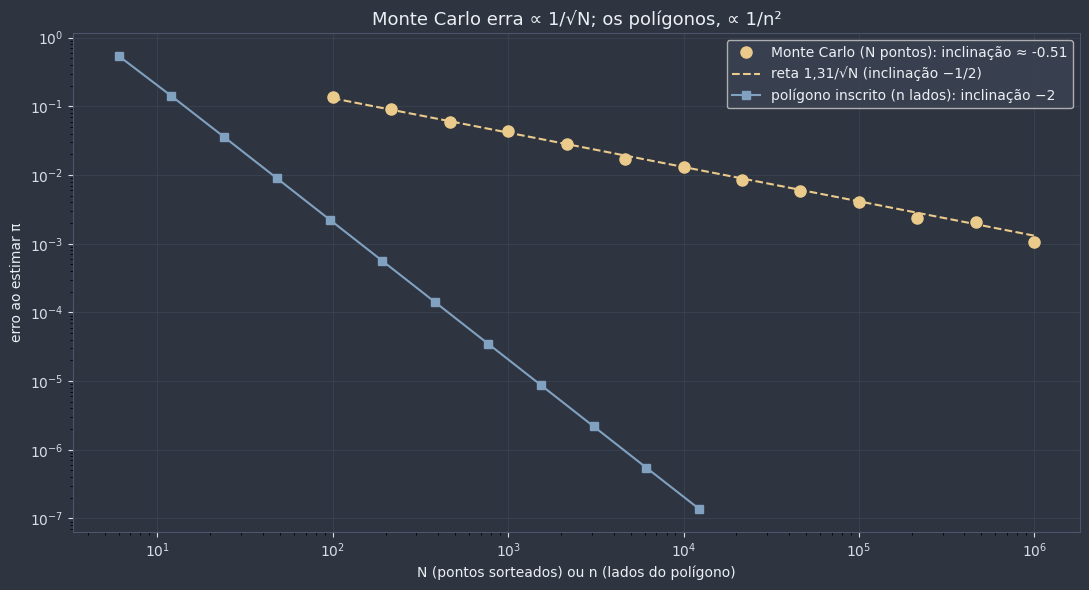

inclinação medida: -0.515 (esperado: −0,5)


In [24]:
Ns = np.unique(np.logspace(2, 6, 13).astype(int))
erros_mc = [np.mean([abs(monte_carlo_area(dentro_circulo, (-1, 1, -1, 1), int(n), semente=s) - math.pi)
                     for s in range(40)]) for n in Ns]
inclinacao = np.polyfit(np.log10(Ns), np.log10(erros_mc), 1)[0]
ns_poligono = [6 * 2**k for k in range(12)]
erros_poligono = [math.pi - area_regular_inscrito(n) for n in ns_poligono]

fig, ax = plt.subplots(figsize=(11, 6))
fig.patch.set_facecolor(NORD_FUNDO)
estilizar_eixo(ax)
ax.loglog(Ns, erros_mc, "o", color=COR_AVISO, ms=8, label=f"Monte Carlo (N pontos): inclinação ≈ {inclinacao:.2f}")
ax.loglog(Ns, 1.31 / np.sqrt(Ns), "--", color=COR_AVISO, lw=1.5, label="reta 1,31/√N (inclinação −1/2)")
ax.loglog(ns_poligono, erros_poligono, "s-", color=COR_POLIGONO, ms=6, label="polígono inscrito (n lados): inclinação −2")
ax.set_xlabel("N (pontos sorteados) ou n (lados do polígono)", color=NORD_TEXTO)
ax.set_ylabel("erro ao estimar π", color=NORD_TEXTO)
ax.set_title("Monte Carlo erra ∝ 1/√N; os polígonos, ∝ 1/n²", color=NORD_TEXTO, fontsize=13)
ax.legend(facecolor=NORD_PAINEL, labelcolor=NORD_TEXTO)
plt.tight_layout()
plt.show()
assert -0.65 < inclinacao < -0.35
print(f"inclinação medida: {inclinacao:.3f} (esperado: −0,5)")

(O número $1{,}31$ não é mágico: dá para calculá-lo com a estatística do módulo 10, a partir da fração $\frac{\pi}{4}$. O que importa aqui é a **inclinação**.)

🕹️ **Widget interativo — estimando $\pi$ com dardos:** escolha o número de pontos $N$ (de 100 a 1 000 000) e a semente do sorteio (cada semente é um "jogo" diferente). Os pontos que caem dentro do círculo ficam azuis; os de fora, vermelhos (no máximo 5 000 são desenhados). Veja a estimativa de $\pi$ e o erro: com $N$ pequeno, o resultado muda muito de uma semente para outra; com $N$ grande, estabiliza, mas devagar.

In [ ]:
def explorar_monte_carlo(N: int, semente: int) -> None:
    gerador = np.random.default_rng(semente)
    x, y = gerador.uniform(-1, 1, N), gerador.uniform(-1, 1, N)
    dentro = x**2 + y**2 <= 1
    estimativa = 4 * dentro.mean()
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14.5, 6.4), gridspec_kw={"width_ratios": [1, 1.05]})
    fig.patch.set_facecolor(NORD_FUNDO)
    m = min(N, 5000)
    ax.scatter(x[:m][dentro[:m]], y[:m][dentro[:m]], s=4 if m > 1000 else 12, color=COR_CIRCULO)
    ax.scatter(x[:m][~dentro[:m]], y[:m][~dentro[:m]], s=4 if m > 1000 else 12, color=COR_SUBTRAIDA)
    desenhar_circunferencia(ax, (0, 0), 1, cor=NORD_TEXTO, largura=1.5)
    preparar_eixo(ax, [(-1, -1), (1, 1)], margem=0.05)
    ax.set_title(f"N = {N:,} pontos (desenhados: {m:,})", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"pontos dentro do círculo: {int(dentro.sum()):,} de {N:,}", True),
        (f"fração dentro = {dentro.mean():.5f}   (π/4 = {math.pi / 4:.5f})", True),
        (f"estimativa: π ≈ 4 × fração = {estimativa:.5f}", True),
        (f"erro = {abs(estimativa - math.pi):.5f}", abs(estimativa - math.pi) < 3 * 1.64 / math.sqrt(N)),
        (f"erro típico esperado ≈ 1,64/√N = {1.64 / math.sqrt(N):.5f}", True),
        (f"pontos para o erro típico cair 10×: {100 * N:,}", True),
    ]
    escrever_checklist(ax_lista, itens, "Monte Carlo")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_monte_carlo,
                 N=widgets.SelectionSlider(options=[100, 300, 1_000, 3_000, 10_000, 30_000, 100_000, 300_000, 1_000_000],
                                           value=1_000, description="N:"),
                 semente=widgets.IntSlider(value=0, min=0, max=20, description="semente:"));

interactive(children=(SelectionSlider(description='N:', index=2, options=(100, 300, 1000, 3000, 10000, 30000, …

🕹️ **Widget interativo — a planta em escala:** um apartamento em "L" de $39$ m² (um retângulo $8 \times 6$ m sem um canto de $3 \times 3$ m) é desenhado numa folha A4 ($21 \times 29{,}7$ cm) em várias escalas $1 : n$. Observe a área no papel encolher com $n^2$, e não com $n$. Em escalas grandes demais (como $1 : 20$), o desenho nem cabe na folha.

In [ ]:
APARTAMENTO = [(0, 0), (8, 0), (8, 3), (5, 3), (5, 6), (0, 6)]  # em metros: 8 × 6 menos 3 × 3 = 39 m²


def explorar_escala(n: int) -> None:
    desenho = np.array(APARTAMENTO) * 100 / n  # metros → centímetros no papel, divididos pela escala
    area_papel = area_cadarco(desenho)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(14, 6.6), gridspec_kw={"width_ratios": [0.9, 1.1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    estilizar_eixo(ax)
    ax.add_patch(Rectangle((0, 0), 29.7, 21, facecolor=NORD_TEXTO, alpha=0.08, edgecolor=NORD_TEXTO_SEC, lw=1.5))
    cabe = desenho[:, 0].max() <= 29.7 and desenho[:, 1].max() <= 21
    desenhar_peca(ax, desenho + 1, cor=COR_SEGMENTO if cabe else COR_SUBTRAIDA, opacidade=0.6)
    ax.set_xlim(0, 45)
    ax.set_ylim(0, 33)
    ax.set_aspect("equal")
    ax.set_xlabel("cm", color=NORD_TEXTO)
    ax.set_title(f"folha A4 (cinza), escala 1 : {n}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"no papel: {800 / n:.2f} cm × {600 / n:.2f} cm (retângulo envolvente)", True),
        (f"área no papel: {area_papel:.2f} cm²", True),
        (f"área real = área no papel × {n}² = {area_real(area_papel, n):,.0f} cm²", True),
        (f"            = {converter_area(area_real(area_papel, n), 'cm²', 'm²'):.2f} m²",
         iguais(converter_area(area_real(area_papel, n), "cm²", "m²"), 39)),
        (f"⚠ multiplicando só por {n}: {converter_area(area_papel * n, 'cm²', 'm²'):.4f} m² (errado)", False),
        ("o desenho cabe na folha A4" if cabe else "o desenho NÃO cabe na folha A4", cabe),
    ]
    escrever_checklist(ax_lista, itens, "Escala 1 : n  ⇒  áreas × n²")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_escala,
                 n=widgets.SelectionSlider(options=[20, 25, 40, 50, 75, 100, 200], value=50, description="1 : n"));

interactive(children=(SelectionSlider(description='1 : n', index=3, options=(20, 25, 40, 50, 75, 100, 200), va…

🎯 **Aplicação prática — mapas, jogos e computação:** áreas de fazendas e reservas aparecem em **hectares**, e um mapa na escala $1 : 50\,000$ transforma cada cm² do papel em $0{,}25$ km² ($25$ ha). Em **jogos e esportes**, dardos e tiro ao alvo premiam mais as regiões menores, justamente as menos prováveis. E o **Monte Carlo** é usado de verdade em física, finanças e computação gráfica, sempre que a região (ou o problema) é complicada demais para uma fórmula.

⚠️ **Erro comum: multiplicar a área por $n$ (em vez de $n^2$) ao mudar de escala.** Os comprimentos crescem $n$ vezes; as áreas, $n^2$ vezes.

⚠️ **Erro comum: converter cm² em m² dividindo por 100.** O certo é dividir por $10\,000$ ($100 \times 100$).

⚠️ **Erro comum: achar que "três regiões" significa "um terço para cada".** As regiões têm áreas diferentes; a probabilidade segue a **área**, não a contagem de regiões.

📖 **Leitura complementar:** [Probabilidade geométrica](https://pt.wikipedia.org/wiki/Probabilidade_geom%C3%A9trica) (com a agulha de Buffon, outro jeito de "sortear" $\pi$), [Método de Monte Carlo](https://pt.wikipedia.org/wiki/M%C3%A9todo_de_Monte_Carlo) e [Alqueire](https://pt.wikipedia.org/wiki/Alqueire) (os vários alqueires do Brasil)

**Pergunta de checagem:** uma planta na escala $1 : 100$ mostra uma sala de $5 \text{ cm} \times 8 \text{ cm}$. Qual é a área real, em m²?

**Pergunta de checagem:** num alvo circular de raio 3, qual é a probabilidade de um dardo cair a menos de 1,5 do centro? E por que, para estimar $\pi$ com uma casa decimal a mais, o Monte Carlo precisa de 100 vezes mais pontos?

## Resumo — cheat sheet

**Notação fixa:** $S$ área; $r$ raio ($R$ o maior); $C = 2\pi r$; $a$ apótema; $p$ semiperímetro; $\alpha$ ângulo central em graus; $\ell_{arco}$ comprimento do arco; $b$ e $h$ base e altura; $B$, $b$, $h$ no trapézio.

| Conceito | Ideia-chave |
|---|---|
| **Polígonos** | quadrado $\ell^2$; retângulo $bh$; paralelogramo $bh$; triângulo $\frac{bh}{2}$; trapézio $\frac{(B + b)h}{2}$; losango $\frac{d_1 d_2}{2}$; regular $p \cdot a$ |
| **Triângulo (outros caminhos)** | Herão $\sqrt{p(p - a)(p - b)(p - c)}$; $p \cdot r$; $\frac{abc}{4R}$; retângulo $\frac{bc}{2}$; equilátero $\frac{\ell^2\sqrt{3}}{4}$; coordenadas $\frac{1}{2}\left\lvert x_1(y_2 - y_3) + x_2(y_3 - y_1) + x_3(y_1 - y_2)\right\rvert$ |
| **Polígono qualquer** | $n - 2$ triângulos (com sinal, vale até para côncavos) |
| **Círculo** | $S = \pi r^2 = \frac{\pi d^2}{4}$: limite de $p \cdot a$ ($p \to \pi r$, $a \to r$); equivale ao triângulo de base $C$ e altura $r$ |
| **Setor** | $\frac{\alpha}{360°}\pi r^2 = \frac{\ell_{arco} \cdot r}{2}$ |
| **Segmento** | setor $-$ triângulo ($\alpha < 180°$), setor $+$ triângulo ($\alpha > 180°$); triângulo $= \frac{\text{corda} \cdot d}{2}$, $d = \sqrt{r^2 - (\text{corda}/2)^2}$ |
| **Coroa** | $\pi(R^2 - r^2)$ = comprimento médio × largura; corda tangente $c$: $\frac{\pi c^2}{4}$ |
| **Razão de áreas** | semelhantes: $k^2$; círculos: $\left(\frac{r_2}{r_1}\right)^2$; escala $1 : n$: $n^2$ |
| **Unidades** | $1$ m² $= 10\,000$ cm²; $1$ ha $= 10\,000$ m²; $1$ km² $= 100$ ha; alqueire paulista $24\,200$ m², mineiro $48\,400$ m² |
| **Regiões compostas** | soma, subtração, simetria, reorganização, proporção; pétala $\left(\frac{\pi}{2} - 1\right)\ell^2$; Reuleaux $\frac{(\pi - \sqrt{3})\ell^2}{2}$; lúnulas $= \frac{bc}{2}$ |
| **Probabilidade geométrica** | $P = \frac{A_{favorável}}{A_{total}}$ (alvo: $\frac{1}{9}, \frac{3}{9}, \frac{5}{9}$; encontro: $\frac{7}{16}$) |
| **Monte Carlo** | área $\approx$ fração dentro × área da caixa; erro $\propto \frac{1}{\sqrt{N}}$ (polígonos: $\propto \frac{1}{n^2}$) |
| **Cuidado** | $\pi r^2 \neq 2\pi r$; diâmetro $\neq$ raio; coroa $\neq \pi(R - r)^2$; Herão usa o **semi**perímetro; cm² → m² divide por $10\,000$ |

**O fio condutor:** polígonos regulares (0418a) → círculo ($p \cdot a$ com $n \to \infty$) → partes do círculo → catálogo e escolha → regiões compostas → aplicações.

## Exercícios

**Básico**
1. Círculos, setores, segmentos e coroas.
2. Qual fórmula usar? (escolha e calcule)
3. Unidades e escala.

**Intermediário**

4. As suas próprias funções: círculo, setor, segmento, coroa, triângulo por coordenadas e polígono.
5. Regiões compostas: pista, moldura, cantos recortados, hexágono entre dois círculos, pétala e Reuleaux.
6. Problemas de dois ou três passos: a anilha, o círculo inscrito e o piso hexagonal.

**Desafio**

7. O Teorema de Pick.
8. Isoperimetria numérica.
9. Monte Carlo × polígonos.
10. As lúnulas, uma por uma.

Gabarito completo com resolução comentada em [`0420b_areas_de_superficies_planas_gabarito.ipynb`](0420b_areas_de_superficies_planas_gabarito.ipynb).

### Básico

In [ ]:
# Exercício Básico 1: círculos, setores, segmentos e coroas (use math.pi e math.sqrt; nada de 3,14).
# (a) Área do círculo de DIÂMETRO 12: guarde em `area_ex1a`.
# (b) Área do setor de 40° num círculo de raio 9: guarde em `area_ex1b`.
# (c) Área do segmento circular de 90° num círculo de raio 4: guarde em `area_ex1c`.
# (d) Área do segmento circular de 120° num círculo de raio 10: guarde em `area_ex1d`
#     (dica: a corda mede 10√3; ache a distância d do centro à corda por Pitágoras).
# (e) Área da coroa entre as circunferências de raios 7 e 3: guarde em `area_ex1e`.
# (f) Área do segmento circular de 240° num círculo de raio 10 (o pedaço "grande"): guarde em `area_ex1f`.
area_ex1a = ...
area_ex1b = ...
area_ex1c = ...
area_ex1d = ...
area_ex1e = ...
area_ex1f = ...

print(area_ex1a, area_ex1b, area_ex1c, area_ex1d, area_ex1e, area_ex1f)

In [ ]:
# Verificação
assert area_ex1a is not ... and math.isclose(area_ex1a, 36 * math.pi), (
    "Tente de novo, revise: com o diâmetro, use πd²/4 (ou o raio 6 em πr²) (seção 1 - A área do círculo)."
)
assert area_ex1b is not ... and math.isclose(area_ex1b, 9 * math.pi), (
    "Tente de novo, revise: o setor é a fração α/360° do círculo (seção 2 - Partes do círculo)."
)
assert area_ex1c is not ... and math.isclose(area_ex1c, 4 * math.pi - 8), (
    "Tente de novo, revise: segmento = setor − triângulo; aqui o triângulo tem catetos 4 e 4 (seção 2 - Partes do círculo)."
)
assert area_ex1d is not ... and math.isclose(area_ex1d, 100 * math.pi / 3 - 25 * math.sqrt(3)), (
    "Tente de novo, revise: d = √(100 − 75) = 5 e o triângulo vale 10√3·5/2 (seção 2 - Partes do círculo)."
)
assert area_ex1e is not ... and math.isclose(area_ex1e, 40 * math.pi), (
    "Tente de novo, revise: a coroa é π(R² − r²), não π(R − r)² (seção 2 - Partes do círculo)."
)
assert area_ex1f is not ... and math.isclose(area_ex1f, 200 * math.pi / 3 + 25 * math.sqrt(3)), (
    "Tente de novo, revise: com α > 180°, o triângulo é SOMADO ao setor (seção 2 - Partes do círculo)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: qual fórmula usar? Para cada situação, guarde em `metodo_ex2x` UMA das chaves abaixo
# (a mais direta para os dados dados) e em `area_ex2x` a área.
# Chaves: "base_altura", "herao", "p_r", "abc_4R", "catetos", "equilatero", "coordenadas", "p_a", "triangulacao"
# (a) Um triângulo de lados 7, 8 e 9.
# (b) O triângulo de vértices (1, 1), (6, 2) e (3, 7).
# (c) Um triângulo retângulo de catetos 9 e 12.
# (d) O octógono regular inscrito numa circunferência de raio 5 (pode usar area_regular ou 2√2·R²).
# (e) Um triângulo de perímetro 30 cuja circunferência inscrita tem raio 2,5.
metodo_ex2a, area_ex2a = ..., ...
metodo_ex2b, area_ex2b = ..., ...
metodo_ex2c, area_ex2c = ..., ...
metodo_ex2d, area_ex2d = ..., ...
metodo_ex2e, area_ex2e = ..., ...

print(metodo_ex2a, area_ex2a, metodo_ex2b, area_ex2b, metodo_ex2c, area_ex2c)
print(metodo_ex2d, area_ex2d, metodo_ex2e, area_ex2e)

In [ ]:
# Verificação
assert metodo_ex2a == "herao" and area_ex2a is not ... and math.isclose(area_ex2a, math.sqrt(720)), (
    "Tente de novo, revise: três lados ⇒ Herão, com p = 12 (seção 3 - O catálogo de fórmulas)."
)
assert metodo_ex2b == "coordenadas" and area_ex2b is not ... and math.isclose(area_ex2b, 14), (
    "Tente de novo, revise: vértices dados ⇒ ½|x₁(y₂ − y₃) + x₂(y₃ − y₁) + x₃(y₁ − y₂)| (seção 3 - O catálogo de fórmulas)."
)
assert metodo_ex2c == "catetos" and area_ex2c is not ... and math.isclose(area_ex2c, 54), (
    "Tente de novo, revise: um cateto é a altura relativa ao outro, S = b·c/2 (seção 3 - O catálogo de fórmulas)."
)
assert metodo_ex2d == "p_a" and area_ex2d is not ... and math.isclose(area_ex2d, 50 * math.sqrt(2)), (
    "Tente de novo, revise: polígono regular ⇒ p·a; o octógono inscrito no raio R vale 2√2·R² "
    "(seção 3 - O catálogo de fórmulas)."
)
assert metodo_ex2e == "p_r" and area_ex2e is not ... and math.isclose(area_ex2e, 37.5), (
    "Tente de novo, revise: S = p·r com o SEMIperímetro, 15 (seção 3 - O catálogo de fórmulas)."
)
print("Certo!")

In [ ]:
# Exercício Básico 3: unidades e escala.
# (a) Quantos cm² há em 3,5 m²? Guarde em `cm2_ex3a`.
# (b) Um terreno retangular de 250 m × 400 m: guarde a área em hectares em `ha_ex3b` e em km² em `km2_ex3b`.
# (c) Numa planta na escala 1 : 200, um cômodo mede 2,5 cm × 3 cm. Guarde a área REAL, em m², em `m2_ex3c`.
# (d) Num mapa na escala 1 : 50 000, uma reserva ocupa 8 cm². Guarde a área real em km² (`km2_ex3d`)
#     e em hectares (`ha_ex3d`).
# (e) Uma fazenda tem 10 alqueires paulistas. Guarde a área em hectares em `ha_ex3e`.
cm2_ex3a = ...
ha_ex3b, km2_ex3b = ..., ...
m2_ex3c = ...
km2_ex3d, ha_ex3d = ..., ...
ha_ex3e = ...

print(cm2_ex3a, ha_ex3b, km2_ex3b, m2_ex3c, km2_ex3d, ha_ex3d, ha_ex3e)

In [ ]:
# Verificação
assert cm2_ex3a is not ... and math.isclose(cm2_ex3a, 35_000), (
    "Tente de novo, revise: 1 m² = 100 cm × 100 cm = 10 000 cm² (seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
assert ha_ex3b is not ... and km2_ex3b is not ... and math.isclose(ha_ex3b, 10) and math.isclose(km2_ex3b, 0.1), (
    "Tente de novo, revise: 100 000 m²; 1 ha = 10 000 m² e 1 km² = 1 000 000 m² "
    "(seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
assert m2_ex3c is not ... and math.isclose(m2_ex3c, 30), (
    "Tente de novo, revise: os lados reais são 5 m e 6 m; a área cresce 200², não 200 "
    "(seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
assert km2_ex3d is not ... and ha_ex3d is not ... and math.isclose(km2_ex3d, 2) and math.isclose(ha_ex3d, 200), (
    "Tente de novo, revise: 8 × 50 000² cm²; depois divida por 10 000 (m²) e por 1 000 000 (km²) "
    "(seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
assert ha_ex3e is not ... and math.isclose(ha_ex3e, 24.2), (
    "Tente de novo, revise: o alqueire paulista tem 24 200 m² (seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 4: as suas próprias funções.
# Complete as funções SEM usar as do notebook (area_circulo, area_setor, area_segmento, area_coroa,
# area_triangulo..., area_poligono, area_cadarco). Pode usar math, numpy, ponto_na_circunferencia e math.dist.
# Nada de seno nem cosseno: no segmento, MEÇA a corda entre as pontas do arco e use Pitágoras para d.
def area_circulo_ex4(r: float) -> float:
    ...


def area_setor_ex4(r: float, alfa: float) -> float:
    ...


def area_segmento_ex4(r: float, alfa: float) -> float:
    # cuidado com α > 180° (e com α = 180°)
    ...


def area_coroa_ex4(R: float, r: float) -> float:
    ...


def area_triangulo_coord_ex4(A, B, C) -> float:
    ...


def area_poligono_ex4(vertices) -> float:
    # n − 2 triângulos a partir do vértice 0, somados COM SINAL (para valer também em côncavos)
    ...


print(area_circulo_ex4(1), area_setor_ex4(6, 60), area_segmento_ex4(6, 60), area_coroa_ex4(5, 3))
print(area_triangulo_coord_ex4((0, 0), (4, 1), (1, 3)), area_poligono_ex4([(0, 0), (6, 3), (0, 6), (2, 3)]))

In [ ]:
# Verificação (contra as funções do notebook, em valores sorteados)
random.seed(4)
for _ in range(200):
    r_v, alfa_v = random.uniform(0.5, 20), random.choice([random.uniform(1, 359), 90, 180, 270])
    assert area_circulo_ex4(r_v) is not None and math.isclose(area_circulo_ex4(r_v), area_circulo(r_v)), (
        "Tente de novo, revise: S = π·r² (seção 1 - A área do círculo)."
    )
    assert math.isclose(area_setor_ex4(r_v, alfa_v), area_setor(r_v, alfa_v)), (
        "Tente de novo, revise: setor = (α/360°)·πr² (seção 2 - Partes do círculo)."
    )
    assert math.isclose(area_segmento_ex4(r_v, alfa_v), area_segmento(r_v, alfa_v), rel_tol=1e-9, abs_tol=1e-9), (
        "Tente de novo, revise: setor − triângulo para α < 180°, setor + triângulo para α > 180° "
        "(seção 2 - Partes do círculo)."
    )
    R_v = r_v + random.uniform(0.1, 10)
    assert math.isclose(area_coroa_ex4(R_v, r_v), area_coroa(R_v, r_v)), (
        "Tente de novo, revise: a coroa é π(R² − r²) (seção 2 - Partes do círculo)."
    )
    P_v = [(random.uniform(-9, 9), random.uniform(-9, 9)) for _ in range(3)]
    assert math.isclose(area_triangulo_coord_ex4(*P_v), area_triangulo_coordenadas(*P_v), abs_tol=1e-9), (
        "Tente de novo, revise: ½|x₁(y₂ − y₃) + x₂(y₃ − y₁) + x₃(y₁ − y₂)| (seção 3 - O catálogo de fórmulas)."
    )
for poligono_v in (terreno, seta, [(0, 0), (4, 0), (4, 4), (2, 1), (0, 4)], vertices_regular(9, 3)):
    assert math.isclose(area_poligono_ex4(poligono_v), area_cadarco(poligono_v)), (
        "Tente de novo, revise: some os n − 2 triângulos V₀VₖVₖ₊₁ com sinal e tire o módulo só no fim "
        "(seção 3 - O catálogo de fórmulas)."
    )
print("Certo!")

In [ ]:
# Exercício Intermediário 5: regiões compostas (escreva a decomposição em palavras antes de calcular).
# (a) Uma pista de atletismo é um retângulo de 100 m × 60 m com dois semicírculos de diâmetro 60 m nas pontas.
#     Guarde a área em `area_ex5a` e o perímetro (o contorno externo) em `perimetro_ex5a`.
# (b) Uma placa quadrada de lado 20 cm tem um furo circular de raio 6 cm. Guarde a área da placa em `area_ex5b`.
# (c) Um quadrado de lado 10 tem, em cada canto, um quarto de círculo de raio 5 recortado. Guarde a área que
#     sobra em `area_ex5c`.
# (d) Hexágono regular de lado 4: guarde a área do hexágono em `hexagono_ex5d`, a do círculo circunscrito em
#     `circunscrito_ex5d`, a do inscrito em `inscrito_ex5d` e a razão inscrito/circunscrito em `razao_ex5d`.
# (e) Complete area_petala_ex5(l) e area_reuleaux_ex5(l) sem usar area_petala nem area_reuleaux.
area_ex5a, perimetro_ex5a = ..., ...
area_ex5b = ...
area_ex5c = ...
hexagono_ex5d, circunscrito_ex5d, inscrito_ex5d, razao_ex5d = ..., ..., ..., ...


def area_petala_ex5(l: float) -> float:
    ...


def area_reuleaux_ex5(l: float) -> float:
    ...


print(area_ex5a, perimetro_ex5a, area_ex5b, area_ex5c)
print(hexagono_ex5d, circunscrito_ex5d, inscrito_ex5d, razao_ex5d, area_petala_ex5(1), area_reuleaux_ex5(1))

In [ ]:
# Verificação
assert area_ex5a is not ... and math.isclose(area_ex5a, 6000 + 900 * math.pi), (
    "Tente de novo, revise: retângulo + dois semicírculos = retângulo + um círculo de raio 30 (seção 4 - Regiões compostas)."
)
assert perimetro_ex5a is not ... and math.isclose(perimetro_ex5a, 200 + 60 * math.pi), (
    "Tente de novo, revise: o contorno são as duas retas de 100 m e uma circunferência inteira de raio 30 "
    "(os lados de 60 m ficam por dentro) (seção 4 - Regiões compostas)."
)
assert area_ex5b is not ... and math.isclose(area_ex5b, 400 - 36 * math.pi), (
    "Tente de novo, revise: subtração, quadrado − círculo (seção 4 - Regiões compostas)."
)
assert area_ex5c is not ... and math.isclose(area_ex5c, 100 - 25 * math.pi), (
    "Tente de novo, revise: os quatro quartos de círculo formam um círculo inteiro de raio 5 (seção 4 - Regiões compostas)."
)
assert hexagono_ex5d is not ... and math.isclose(hexagono_ex5d, 24 * math.sqrt(3)), (
    "Tente de novo, revise: seis equiláteros de lado 4, ou (3√3/2)·ℓ² (seção 3 - O catálogo de fórmulas)."
)
assert circunscrito_ex5d is not ... and inscrito_ex5d is not ... and math.isclose(circunscrito_ex5d, 16 * math.pi) \
    and math.isclose(inscrito_ex5d, 12 * math.pi), (
    "Tente de novo, revise: o raio circunscrito é o lado (4) e o inscrito é o apótema, 2√3 (seção 1 - A área do círculo)."
)
assert razao_ex5d is not ... and math.isclose(razao_ex5d, 0.75), (
    "Tente de novo, revise: a razão é (a/R)² = (√3/2)² (seção 1 - A área do círculo)."
)
for l_v in (1, 2, 10, 0.3):
    assert area_petala_ex5(l_v) is not None and math.isclose(area_petala_ex5(l_v), (math.pi / 2 - 1) * l_v**2), (
        "Tente de novo, revise: dois quartos de círculo cobrem o quadrado e a pétala duas vezes (seção 4 - Regiões compostas)."
    )
    assert area_reuleaux_ex5(l_v) is not None and math.isclose(area_reuleaux_ex5(l_v), (math.pi - math.sqrt(3)) / 2 * l_v**2), (
        "Tente de novo, revise: três setores de 60° menos DUAS vezes o triângulo equilátero (seção 4 - Regiões compostas)."
    )
print("Certo!")

In [ ]:
# Exercício Intermediário 6: problemas de dois ou três passos.
# (a) A anilha: numa coroa circular, a corda da circunferência externa que tangencia a interna mede 24 cm.
#     Guarde a área da coroa em `area_ex6a`. Se o raio interno é 5 cm, guarde o raio externo em `R_ex6a`.
# (b) Que fração da área de um triângulo é ocupada pelo seu círculo inscrito? Guarde em `fracao_ex6b` a fração
#     para o triângulo 13–14–15 e em `fracao_345_ex6b` a fração para o triângulo 3–4–5.
#     (Dica: r = S/p.)
# (c) Uma cozinha tem a forma de um hexágono regular de lado 3 m. O piso custa R$ 60,00 o m² e é preciso comprar
#     10% a mais por causa dos cortes. Guarde a área da cozinha em `area_ex6c`, a área de piso a comprar em
#     `comprar_ex6c` e o custo em `custo_ex6c`.
area_ex6a, R_ex6a = ..., ...
fracao_ex6b, fracao_345_ex6b = ..., ...
area_ex6c, comprar_ex6c, custo_ex6c = ..., ..., ...

print(area_ex6a, R_ex6a, fracao_ex6b, fracao_345_ex6b, area_ex6c, comprar_ex6c, custo_ex6c)

In [ ]:
# Verificação
assert area_ex6a is not ... and math.isclose(area_ex6a, 144 * math.pi), (
    "Tente de novo, revise: R² − r² = (c/2)², então a coroa é πc²/4 (seção 2 - Partes do círculo)."
)
assert R_ex6a is not ... and math.isclose(R_ex6a, 13), (
    "Tente de novo, revise: R² = r² + 12² (seção 2 - Partes do círculo)."
)
assert fracao_ex6b is not ... and math.isclose(fracao_ex6b, 16 * math.pi / 84), (
    "Tente de novo, revise: r = 84/21 = 4; a fração é πr²/S (seção 3 - O catálogo de fórmulas)."
)
assert fracao_345_ex6b is not ... and math.isclose(fracao_345_ex6b, math.pi / 6), (
    "Tente de novo, revise: S = 6, p = 6, r = 1 (seção 3 - O catálogo de fórmulas)."
)
assert area_ex6c is not ... and math.isclose(area_ex6c, 13.5 * math.sqrt(3)), (
    "Tente de novo, revise: o hexágono são seis equiláteros de lado 3, ou (3√3/2)·ℓ² (seção 3 - O catálogo de fórmulas)."
)
assert comprar_ex6c is not ... and custo_ex6c is not ... and math.isclose(comprar_ex6c, 1.1 * 13.5 * math.sqrt(3)) \
    and math.isclose(custo_ex6c, 66 * 13.5 * math.sqrt(3)), (
    "Tente de novo, revise: área × 1,10 e depois × R$ 60,00 (seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 7: o Teorema de Pick.
# Para um polígono simples cujos vértices são pontos de coordenadas INTEIRAS, o Teorema de Pick diz que
#     S = I + B/2 − 1,
# onde I é o número de pontos inteiros no INTERIOR e B o número de pontos inteiros na BORDA (vértices incluídos).
# Complete pick_ex7(vertices), que devolve a tupla (I, B) contando os pontos:
#   - B: num lado de (x₁, y₁) até (x₂, y₂), há mdc(|x₂ − x₁|, |y₂ − y₁|) pontos inteiros, sem contar um dos extremos
#     (use math.gcd);
#   - I: percorra os pontos inteiros do retângulo envolvente e conte os que estão dentro e fora da borda
#     (para "dentro", conte quantos lados uma semirreta horizontal saindo do ponto cruza: ímpar = dentro).
# Depois, confira à mão o triângulo (0, 0), (4, 1), (1, 3) da seção 3: S = 5,5.
def pick_ex7(vertices) -> tuple[int, int]:
    ...


print(pick_ex7([(0, 0), (4, 1), (1, 3)]), pick_ex7([(0, 0), (4, 0), (4, 4), (0, 4)]))

In [ ]:
# Verificação (o triângulo do texto, um quadrado e 150 polígonos sorteados, convexos ou não)
assert pick_ex7([(0, 0), (4, 1), (1, 3)]) == (5, 3), (
    "Tente de novo, revise: B = 3 (só os vértices) e I = 5, pois 5,5 = 5 + 3/2 − 1 (seção 3 - O catálogo de fórmulas)."
)
assert pick_ex7([(0, 0), (4, 0), (4, 4), (0, 4)]) == (9, 16), (
    "Tente de novo, revise: o quadrado 4 × 4 tem 16 pontos na borda e 9 dentro (seção 3 - O catálogo de fórmulas)."
)
gerador_v = random.Random(7)
for _ in range(150):
    pts_v = list({(gerador_v.randint(-6, 6), gerador_v.randint(-6, 6)) for _ in range(gerador_v.randint(3, 10))})
    if len(pts_v) < 3:
        continue
    cx_v = sum(p[0] for p in pts_v) / len(pts_v) + 0.0137
    cy_v = sum(p[1] for p in pts_v) / len(pts_v) + 0.0071
    pts_v.sort(key=lambda p: math.atan2(p[1] - cy_v, p[0] - cx_v))  # polígono "estrelado": simples
    if area_cadarco(pts_v) < 0.5:
        continue
    I_v, B_v = pick_ex7(pts_v)
    B_esperado_v = sum(math.gcd(abs(q[0] - p[0]), abs(q[1] - p[1])) for p, q in zip(pts_v, pts_v[1:] + pts_v[:1]))
    assert B_v == B_esperado_v, (
        "Tente de novo, revise: B é a soma, lado a lado, de mdc(|Δx|, |Δy|) (seção 3 - O catálogo de fórmulas)."
    )
    assert math.isclose(I_v + B_v / 2 - 1, area_cadarco(pts_v)), (
        "Tente de novo, revise: conte em I só os pontos estritamente dentro (os da borda já estão em B) "
        "(seção 3 - O catálogo de fórmulas)."
    )
print("Certo!")

In [ ]:
# Exercício Desafio 8: isoperimetria numérica. Todas as figuras abaixo têm PERÍMETRO 12.
# (a) Guarde em `areas_ex8` um dicionário com as áreas do triângulo equilátero (chave 3), do quadrado (chave 4),
#     do hexágono regular (chave 6) e do círculo (chave "círculo").
# (b) Guarde em `lista_ex8` a lista das áreas dos polígonos regulares de perímetro 12 com n = 3, 4, ..., 40 lados
#     (dica: faça o regular de n lados inscrito no raio 1 com vertices_regular, meça o perímetro e AMPLIE com a
#     razão k = 12/perímetro: a área fica multiplicada por k²).
# (c) Guarde em `conclusao_ex8` a palavra "círculo" ou "quadrado", respondendo: entre todas essas figuras de mesmo
#     perímetro, qual tem a maior área?
areas_ex8 = ...
lista_ex8 = ...
conclusao_ex8 = ...

print(areas_ex8)
print([round(s, 4) for s in lista_ex8[:6]], "...", round(lista_ex8[-1], 4))

In [ ]:
# Verificação
assert areas_ex8 is not ... and math.isclose(areas_ex8[3], 4 * math.sqrt(3)) and math.isclose(areas_ex8[4], 9), (
    "Tente de novo, revise: equilátero de lado 4 (ℓ²√3/4) e quadrado de lado 3 (seção 3 - O catálogo de fórmulas)."
)
assert math.isclose(areas_ex8[6], 6 * math.sqrt(3)) and math.isclose(areas_ex8["círculo"], 36 / math.pi), (
    "Tente de novo, revise: hexágono de lado 2, (3√3/2)·4; círculo com 2πr = 12, r = 6/π (seção 1 - A área do círculo)."
)
assert lista_ex8 is not ... and len(lista_ex8) == 38 and math.isclose(lista_ex8[0], areas_ex8[3]), (
    "Tente de novo, revise: n vai de 3 a 40, ou seja, 38 polígonos (seção 3 - O catálogo de fórmulas)."
)
assert all(x < y for x, y in zip(lista_ex8, lista_ex8[1:])) and lista_ex8[-1] < 36 / math.pi, (
    "Tente de novo, revise: amplie cada polígono pela razão k = 12/perímetro; a área vai × k² "
    "(seção 1 - A área do círculo)."
)
assert conclusao_ex8 == "círculo", "Tente de novo, revise: compare cada valor com 36/π (seção 1 - A área do círculo)."
print("Certo!")

In [ ]:
# Exercício Desafio 9: Monte Carlo × polígonos, com o mesmo "custo".
# Estimar π com um polígono de n lados custa umas n contas; com Monte Carlo de n pontos, também umas n contas.
# Para n = 6, 24, 96, 384, 1536 e 6144:
# (a) `erros_poligono_ex9`: lista dos erros π − area_regular_inscrito(n) (polígono inscrito, R = 1).
# (b) `erros_mc_ex9`: lista dos erros |estimativa − π| de monte_carlo_area(dentro_circulo, (-1, 1, -1, 1), n,
#     semente=0).
# (c) `razao_ex9`: por quanto o erro do polígono é dividido quando n é multiplicado por 4 (de 6 para 24)?
# (d) `vencedor_ex9`: "polígonos" ou "monte carlo" — qual método foi mais preciso para n = 6144?
ns_ex9 = [6, 24, 96, 384, 1536, 6144]
erros_poligono_ex9 = ...
erros_mc_ex9 = ...
razao_ex9 = ...
vencedor_ex9 = ...

print(erros_poligono_ex9, erros_mc_ex9, razao_ex9, vencedor_ex9, sep="\n")

In [ ]:
# Verificação
assert erros_poligono_ex9 is not ... and len(erros_poligono_ex9) == 6 and all(
    math.isclose(e, math.pi - area_regular_inscrito(n)) for e, n in zip(erros_poligono_ex9, ns_ex9)), (
    "Tente de novo, revise: o erro é π − S, com S = p·a do inscrito (seção 1 - A área do círculo)."
)
assert erros_mc_ex9 is not ... and len(erros_mc_ex9) == 6 and all(
    math.isclose(e, abs(monte_carlo_area(dentro_circulo, (-1, 1, -1, 1), n, semente=0) - math.pi))
    for e, n in zip(erros_mc_ex9, ns_ex9)), (
    "Tente de novo, revise: use semente=0 e o valor absoluto da diferença "
    "(seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
assert razao_ex9 is not ... and 14 < razao_ex9 < 17, (
    "Tente de novo, revise: n × 4 = duas dobras; cada dobra divide o erro por ~4 (seção 1 - A área do círculo)."
)
assert vencedor_ex9 == "polígonos", (
    "Tente de novo, revise: compare os últimos elementos das duas listas (seção 5 - Escala, unidades, probabilidade e Monte Carlo)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 10: as lúnulas, uma por uma (numericamente).
# No triângulo retângulo A = (0, 0), B = (c, 0), C = (0, b), cada lúnula é a região dentro do semicírculo
# construído PARA FORA sobre um cateto e fora do círculo de diâmetro BC (a hipotenusa).
# Complete lunulas_ex10(b, c, n), que devolve (lunula_sobre_AC, lunula_sobre_AB): construa cada lúnula como um
# polígono (n pontos sobre o arco pequeno, de uma ponta do cateto à outra, e n pontos voltando pelo arco grande)
# e meça com area_cadarco. Use pontos_arco, ponto_medio e direcao_de; NÃO use lunula_pontos nem area_lunulas.
# Depois, observe: cada lúnula sozinha tem um valor "feio", mas a soma das duas é exatamente b·c/2.
def lunulas_ex10(b: float, c: float, n: int = 2000) -> tuple[float, float]:
    ...


print(lunulas_ex10(3, 4), sum(lunulas_ex10(3, 4)), 3 * 4 / 2)

In [ ]:
# Verificação
for b_v, c_v in ((3, 4), (1, 1), (5, 12), (2, 7), (6, 2.5)):
    resultado_v = lunulas_ex10(b_v, c_v)
    assert resultado_v is not None and math.isclose(sum(resultado_v), b_v * c_v / 2, rel_tol=1e-5), (
        "Tente de novo, revise: a soma das duas lúnulas deve dar b·c/2; confira por onde passa cada arco "
        "(seção 4 - Regiões compostas)."
    )
    referencia_v = (area_cadarco(lunula_pontos(b_v, c_v, "b")), area_cadarco(lunula_pontos(b_v, c_v, "c")))
    assert all(math.isclose(x, y, rel_tol=1e-4) for x, y in zip(resultado_v, referencia_v)), (
        "Tente de novo, revise: a primeira lúnula é a do cateto AC (de medida b), a segunda a do cateto AB "
        "(seção 4 - Regiões compostas)."
    )
assert math.isclose(lunulas_ex10(2, 2)[0], lunulas_ex10(2, 2)[1]), (
    "Tente de novo, revise: no triângulo isósceles, as duas lúnulas são congruentes (seção 4 - Regiões compostas)."
)
print("Certo!")

## Fechamento do módulo — Geometria Plana em retrospectiva

Este é o último notebook do módulo 04. Vale parar um minuto e olhar o caminho inteiro.

### Os 20 notebooks em seis arcos

1. **Fundamentos (0401–0403):** noções primitivas, segmentos, ângulos.
2. **Triângulos e paralelas (0404–0407):** classificação, congruência, paralelismo (a soma $180°$), perpendicularidade.
3. **Quadriláteros e polígonos (0408–0411):** trapézios, paralelogramos, pontos notáveis do triângulo, polígonos.
4. **Circunferência (0412–0413):** círculo, tangentes, arcos e ângulos.
5. **Proporção e métrica (0414–0417):** Tales, semelhança, potência de ponto, Pitágoras, Herão e Stewart.
6. **Medidas (0418–0420):** polígonos regulares, $\pi$, equivalência e áreas.

### Os fios que atravessaram o módulo

- **Lugares geométricos:** mediatriz (0407) → bissetriz (0410) → circunferência (0412) → arco capaz (0413) → circunferência de Apolônio (0414) → eixo radical e potência de ponto (0415).
- **A cadeia da proporção:** Tales (0414) → semelhança (0415) → relações métricas e **Pitágoras** (0416) → Pitágoras generalizado (0417) → Pitágoras por áreas (0419).
- **Do reto ao curvo:** polígonos com cada vez mais lados (0411, 0418) → circunferência → $\pi$ → área do círculo (0420).
- **A área:** trapézio e base média (0408) → paralelogramos (0409) → Herão e $p \cdot r$ (0417) → $p \cdot a$ (0418) → o porquê das fórmulas (0419) → o catálogo e o círculo (0420).
- **Demonstrar × verificar:** o módulo inteiro alternou **demonstrações** curtas e **verificações numéricas** em código. Não esqueça a diferença: a verificação numérica **ilustra** (e pega erros), a demonstração **garante**. Nenhuma quantidade de `assert` prova um teorema; mas um único `assert` que falha derruba uma conjectura.

O mapa abaixo desenha os 20 notebooks como estações e os fios como **linhas de metrô**.

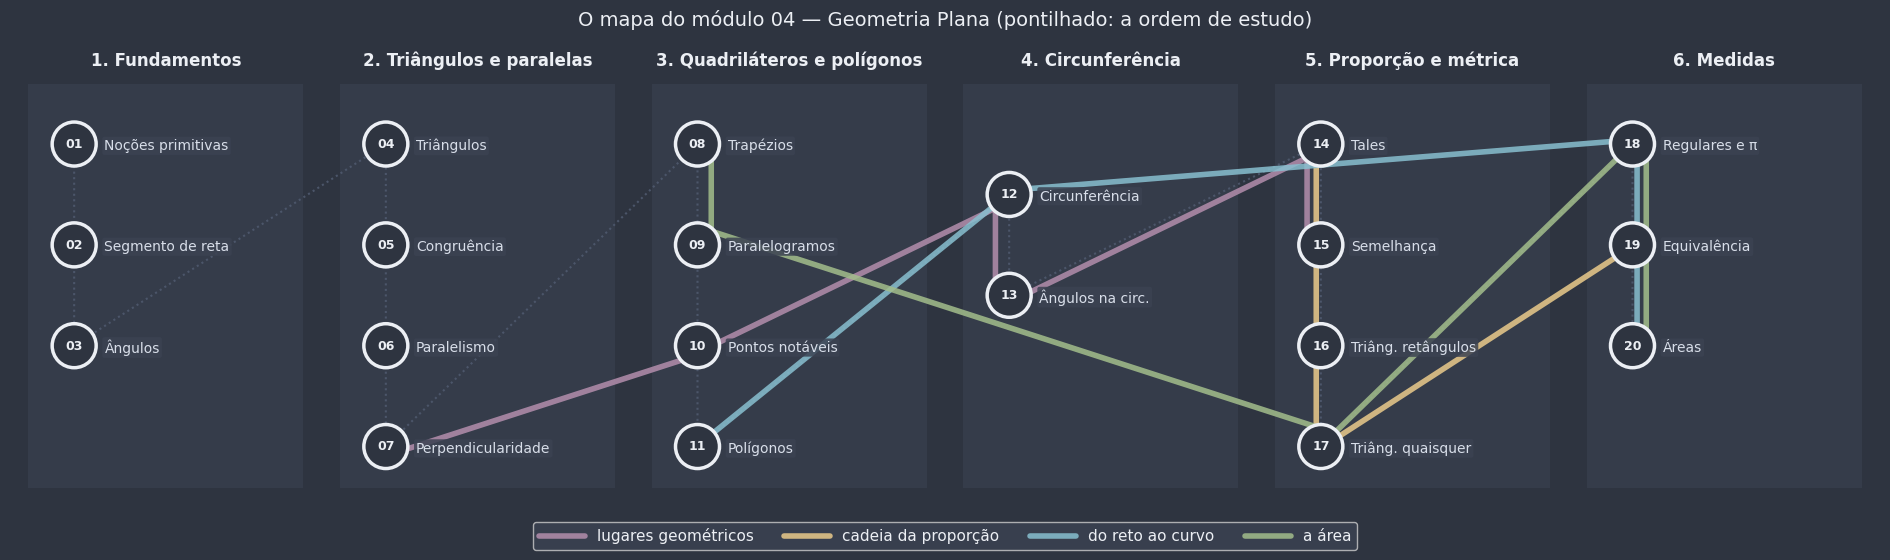

In [27]:
ESTACOES = {
    1: "Noções primitivas", 2: "Segmento de reta", 3: "Ângulos", 4: "Triângulos", 5: "Congruência",
    6: "Paralelismo", 7: "Perpendicularidade", 8: "Trapézios", 9: "Paralelogramos", 10: "Pontos notáveis",
    11: "Polígonos", 12: "Circunferência", 13: "Ângulos na circ.", 14: "Tales", 15: "Semelhança",
    16: "Triâng. retângulos", 17: "Triâng. quaisquer", 18: "Regulares e π", 19: "Equivalência", 20: "Áreas",
}
ARCOS = [("Fundamentos", [1, 2, 3]), ("Triângulos e paralelas", [4, 5, 6, 7]),
         ("Quadriláteros e polígonos", [8, 9, 10, 11]), ("Circunferência", [12, 13]),
         ("Proporção e métrica", [14, 15, 16, 17]), ("Medidas", [18, 19, 20])]
LINHAS_METRO = [
    ("lugares geométricos", COR_EXTRA, [7, 10, 12, 13, 14, 15]),
    ("cadeia da proporção", COR_AVISO, [14, 15, 16, 17, 19]),
    ("do reto ao curvo", COR_PONTO, [11, 12, 18, 20]),
    ("a área", COR_DESTAQUE, [8, 9, 17, 18, 19, 20]),
]
posicao = {}
for coluna, (_, estacoes) in enumerate(ARCOS):
    for linha, numero in enumerate(estacoes):
        posicao[numero] = np.array([3.4 * coluna, 3 - 1.1 * linha - (0.55 if len(estacoes) == 2 else 0)])

fig, ax = plt.subplots(figsize=(19, 7.5))
fig.patch.set_facecolor(NORD_FUNDO)
ax.set_facecolor(NORD_FUNDO)
for coluna, (nome, estacoes) in enumerate(ARCOS):
    ax.add_patch(Rectangle((3.4 * coluna - 0.5, -0.75), 3.0, 4.4, facecolor=NORD_PAINEL, alpha=0.6, edgecolor="none"))
    ax.text(3.4 * coluna + 1.0, 3.85, f"{coluna + 1}. {nome}", color=NORD_TEXTO, fontsize=12, fontweight="bold",
            ha="center")
# A ordem de estudo (linha fina) e as quatro linhas de metrô, levemente deslocadas para não se sobreporem
ax.plot(*np.array([posicao[k] for k in range(1, 21)]).T, color=NORD_LINHA, lw=1.5, ls=":", zorder=1)
for k, (nome, cor, estacoes) in enumerate(LINHAS_METRO):
    desvio = np.array([0.1 * (k - 1.5), 0.1 * (k - 1.5)])
    ax.plot(*np.array([posicao[e] + desvio for e in estacoes]).T, color=cor, lw=4, alpha=0.85, zorder=2,
            solid_capstyle="round", label=nome)
for numero, nome in ESTACOES.items():
    x, y = posicao[numero]
    ax.add_patch(Circle((x, y), 0.24, facecolor=NORD_FUNDO, edgecolor=NORD_TEXTO, lw=2.5, zorder=5))
    ax.text(x, y, f"{numero:02d}", color=NORD_TEXTO, fontsize=9, fontweight="bold", ha="center", va="center", zorder=6)
    ax.text(x + 0.33, y - 0.02, nome, color=NORD_TEXTO_SEC, fontsize=10, va="center", zorder=6,
            bbox={"boxstyle": "round,pad=0.15", "facecolor": NORD_PAINEL, "edgecolor": "none", "alpha": 0.85})
ax.legend(loc="lower center", ncol=5, facecolor=NORD_PAINEL, labelcolor=NORD_TEXTO, bbox_to_anchor=(0.5, -0.12),
          fontsize=11, handlelength=3)
ax.set_xlim(-0.7, 3.4 * 5 + 2.7)
ax.set_ylim(-0.9, 4.2)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("O mapa do módulo 04 — Geometria Plana (pontilhado: a ordem de estudo)", color=NORD_TEXTO, fontsize=14)
plt.tight_layout()
plt.show()

### O que cada ideia vira nos próximos módulos

- **Trigonometria** ([`05_trigonometria/`](../05_trigonometria/)): as razões da semelhança viram seno, cosseno e tangente; a área do triângulo ganha a forma $S = \frac{1}{2} a b \operatorname{sen} C$; o ângulo ganha uma nova unidade, o **radiano**, e o setor passa a valer $S = \frac{1}{2} r^2 \theta$.
- **Geometria Analítica:** distância entre pontos (Pitágoras), a fórmula do cadarço demonstrada, retas e circunferências por equações, o baricentro como média das coordenadas.
- **Geometria Espacial:** as mesmas ideias em 3D, com áreas de superfícies (prismas, pirâmides, cilindros, cones, esfera), volumes pelo princípio de Cavalieri e a razão $k^3$.
- **Números Complexos e Vetores:** módulo e norma são a distância de Pitágoras com outro nome.
- **Cálculo:** o "$n \to \infty$" dos polígonos vira **limite**, e a cebola vira a **integral**: área como soma de infinitas fatias finas.
- **Probabilidade:** área como probabilidade, e o Monte Carlo como ferramenta.

### 💡 Mini-projeto final (opcional): a sua calculadora geométrica

Reúna, num único arquivo `geometria_plana.py` (ou numa seção nova deste notebook), as funções que você construiu ao longo do módulo: distância e ponto médio, ângulos, triângulos (Herão, centros, raios, medianas), polígonos regulares, círculo e suas partes, o catálogo de áreas e o Monte Carlo. Acrescente uma **suíte de testes** com `assert` (os triângulos 3–4–5 e 13–14–15 são ótimos casos de teste). E use a calculadora no **seu** problema: a planta do seu quarto, o terreno da sua casa, a pizza da sexta-feira.

### Para terminar

Você começou o módulo com ponto, reta e plano, coisas que ninguém define, e terminou medindo o círculo. No caminho, só usou uma regra: **tudo se prova a partir do que já está provado**.

## Conexões

**Isso depende de:**
- [`0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb`](0408a_quadrilateros_definicao_elementos_e_trapezios.ipynb) (trapézio e base média: a área como base média × altura)
- [`0409a_paralelogramos_e_casos_particulares.ipynb`](0409a_paralelogramos_e_casos_particulares.ipynb) (paralelogramo, retângulo, losango e quadrado, agora no catálogo)
- [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb) (triangulação em $n - 2$ triângulos: a área de qualquer polígono)
- [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (círculo, corda, distância do centro à corda, tangente perpendicular ao raio, coroa)
- [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (ângulo central e arco: a proporção do setor; ângulo inscrito na semicircunferência, nas lúnulas)
- [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (proporcionalidade, base da semelhança)
- [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (razão de semelhança: escalas, maquetes e "todo círculo é semelhante a todo outro")
- [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (Pitágoras: segmento circular, anilha, equilátero, lúnulas)
- [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) (Herão, $S = p \cdot r$ e $S = \frac{abc}{4R}$, reunidos e comparados)
- [`0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb`](0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb) ($S = p \cdot a$, a dobra dos lados, $C = 2\pi r$ e o comprimento do arco)
- [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb) (o porquê das fórmulas, a régua de área, a razão $k^2$ e as lúnulas de Hipócrates)
- Referência cruzada: [`0302a_progressao_aritmetica.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0302a_progressao_aritmetica.ipynb) (a soma dos ímpares, no alvo) e [`0305a_determinantes.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0305a_determinantes.ipynb) (área de triângulos por determinante, parente da fórmula das coordenadas)

**Isso será usado em:**
- [`0501a_arcos_e_angulos.ipynb`](../05_trigonometria/0501a_arcos_e_angulos.ipynb) (o radiano; com ele, o setor de ângulo $\theta$ passa a valer $S = \frac{1}{2} r^2 \theta$)
- [`0510a_triangulos_quaisquer.ipynb`](../05_trigonometria/0510a_triangulos_quaisquer.ipynb) (a área do triângulo com trigonometria, $S = \frac{1}{2} a b \operatorname{sen} C$, ao lado de Herão)
- 📌 Geometria Espacial (áreas laterais e totais de prismas, pirâmides, cilindros, cones e esfera; volumes por Cavalieri; razão $k^3$)
- 📌 Geometria Analítica (a fórmula do cadarço demonstrada; áreas de regiões limitadas por retas e circunferências)
- 📌 Análise Combinatória e Probabilidade (probabilidade geométrica e simulações de Monte Carlo)
- 📌 Limite, Integral e Derivada (a área como limite de somas e como integral; a cebola é a "integração em anéis")